# Практическая работа № 6. Обработка текстовых данных в Spark MLlib

Выполнил: Савинский Владимир Олегович, ИКБО-40-23, 03.11.2026

**Цель:** построить воспроизводимый процесс обработки литературного корпуса: от проверки кодировок и границ произведений до классификации авторов и генерации текста.

**Классификация:** определение автора 300-словного фрагмента художественной прозы. Авторы - **Брюсов, Герцен и Пушкин**. Качество оценивается по фрагментам и произведениям.

**Генерация:** цепи Маркова первого и второго порядка по train-произведениям **Достоевского**.

**Данные:** Literature.zip, 373 TXT-файла. Для классификации отобраны 17 файлов Брюсова, 8 Герцена и 9 Пушкина, для генерации - 12 произведений Достоевского. Разрешённый методичкой выбор других авторов сохраняет один тип текстов - художественную прозу.

Численные выводы и подробные разборы ниже относятся к контрольному расчёту на этом архиве. После повторного запуска их следует сверить с таблицами: время и отдельные значения зависят от окружения.

### Подготовка окружения

In [1]:
import os
import sys
from pathlib import Path

EXPECTED_PYTHON = r"D:\BigData_Practicies\venv\Scripts\python.exe"
JAVA = r"C:\Program Files\Java\jdk-21.0.12.1"
HADOOP = r"D:\hadoop"
KAGGLE_CACHE = r"D:\BigData_Practicies\data\kagglehub_cache"

if os.name == "nt":
    if os.path.normcase(os.path.abspath(sys.executable)) != os.path.normcase(EXPECTED_PYTHON):
        raise RuntimeError(
            "Выбрано другое ядро Jupyter. Нужен существующий интерпретатор: "
            + EXPECTED_PYTHON
            + "\nТекущий: "
            + sys.executable
        )

    os.environ["JAVA_HOME"] = JAVA
    os.environ["HADOOP_HOME"] = HADOOP
    os.environ["KAGGLEHUB_CACHE"] = KAGGLE_CACHE

    for directory in [Path(HADOOP) / "bin", Path(JAVA) / "bin"]:
        if str(directory) not in os.environ.get("PATH", "").split(os.pathsep):
            os.environ["PATH"] = str(directory) + os.pathsep + os.environ.get("PATH", "")

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
PREVIOUS_SPARK_HOME = os.environ.pop("SPARK_HOME", None)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["SPARK_LOCAL_HOSTNAME"] = "localhost"

print("Python      :", sys.version.split()[0], "|", sys.executable)
print("JAVA_HOME   :", os.environ.get("JAVA_HOME"))
print("HADOOP_HOME :", os.environ.get("HADOOP_HOME"))
print("KAGGLEHUB_CACHE:", os.environ.get("KAGGLEHUB_CACHE"))

Python      : 3.15.0 | D:\BigData_Practicies\venv\Scripts\python.exe
JAVA_HOME   : C:\Program Files\Java\jdk-21.0.12.1
HADOOP_HOME : D:\hadoop
KAGGLEHUB_CACHE: D:\BigData_Practicies\data\kagglehub_cache
SPARK_HOME сброшен для этого ядра: D:\SPARK\spark-4.2.0-bin-hadoop3\spark-4.2.0-bin-hadoop3


In [2]:
import json
import math
import hashlib
import random
import platform
import re
import subprocess
import warnings
from pathlib import PurePosixPath
from zipfile import ZipFile
from collections import Counter, defaultdict
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import pyspark
from pyspark.find_spark_home import _find_spark_home
from pyspark.sql import SparkSession, functions as F, types as T, Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (
    RegexTokenizer,
    StopWordsRemover,
    CountVectorizer,
    CountVectorizerModel,
    IDF,
    Normalizer,
    NGram,
    HashingTF,
)
from pyspark.ml.classification import NaiveBayes, LogisticRegression
from pyspark.ml.functions import vector_to_array, array_to_vector

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.figsize": (9, 4.5)})
print("PySpark:", pyspark.__version__, "|", Path(pyspark.__file__).parent)

PySpark: 4.2.0 | D:\BigData_Practicies\venv\Lib\site-packages\pyspark


In [3]:
ROOT = Path.cwd().resolve()
LIT_SOURCE = ROOT / "Literature.zip"
WORK = ROOT / "data_pr6_literature"
OUT = ROOT / "results_pr6_literature"

print("Рабочий каталог:", ROOT)
print("Архив:", LIT_SOURCE)
print("Архив найден:", LIT_SOURCE.is_file())

if not LIT_SOURCE.is_file():
    raise FileNotFoundError(
        f"В рабочем каталоге Jupyter нет {LIT_SOURCE.name}: {ROOT}\n"
        "Проверь каталог, из которого запущено ядро. Нужен каталог с ноутбуком и архивом."
    )

WORK.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

SEED = 42
AUTHORS = ["Bryusov", "Herzen", "Pushkin"]
AUTHOR_RU = {
    "Bryusov": "Брюсов",
    "Herzen": "Герцен",
    "Pushkin": "Пушкин",
    "Dostoevsky": "Достоевский",
}
LABEL_NAMES = {i: AUTHOR_RU[author] for i, author in enumerate(AUTHORS)}
K = len(AUTHORS)
GEN_AUTHOR = "Dostoevsky"
FRAGMENT_WORDS = 300
MAX_TRAIN_FRAGMENTS = 50
VOCAB_SIZE = 20000
MIN_DF = 3.0
REG_PARAM = 0.001
GEN_SENTENCES_PER_WORK = 200
MAX_EDGES = 200000

Рабочий каталог: D:\BigData_Practicies
Архив: D:\BigData_Practicies\Literature.zip
Архив найден: True


In [4]:
SPARK_DISTRIBUTION = Path(_find_spark_home())
SPARK_SUBMIT = (
    SPARK_DISTRIBUTION / "bin" / ("spark-submit.cmd" if os.name == "nt" else "spark-submit")
)

if not SPARK_SUBMIT.is_file():
    raise FileNotFoundError(
        "Не найден запускающий файл Spark: "
        + str(SPARK_SUBMIT)
        + "\nПроверь состав установленного PySpark в выбранном venv."
    )

if os.name == "nt":
    java_executable = Path(os.environ["JAVA_HOME"]) / "bin" / "java.exe"
    winutils = Path(os.environ["HADOOP_HOME"]) / "bin" / "winutils.exe"
    command_shell = Path(
        os.environ.get("COMSPEC")
        or str(Path(os.environ.get("SystemRoot", r"C:\Windows")) / "System32" / "cmd.exe")
    )

    for required in [java_executable, winutils, command_shell]:
        if not required.is_file():
            raise FileNotFoundError(f"Не найден файл окружения: {required}")

    os.environ["COMSPEC"] = str(command_shell)
    java_version = subprocess.run(
        [str(java_executable), "-version"],
        capture_output=True,
        text=True,
        timeout=15,
        check=True,
    )
    print((java_version.stderr or java_version.stdout).splitlines()[0])

print("Запускающий файл Spark:", SPARK_SUBMIT)

java version "21.0.12.1" 2026-08-18 LTS
Запускающий файл Spark: D:\BigData_Practicies\venv\Lib\site-packages\pyspark\bin\spark-submit.cmd


In [5]:
spark = (
    SparkSession.builder.master("local[*]")
    .appName("PR6_Literature_MLlib")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
sc = spark.sparkContext
sc.setLogLevel("ERROR")

assert spark.range(3).count() == 3
assert sc.parallelize([1, 2, 3], 1).map(lambda number: number + 1).collect() == [2, 3, 4]

print(
    "Spark",
    spark.version,
    "| ядер (defaultParallelism):",
    sc.defaultParallelism,
    "| UI:",
    sc.uiWebUrl,
)
print("JVM и Python worker: OK")

Spark 4.2.0 | ядер (defaultParallelism): 20 | UI: http://127.0.0.1:4040
JVM и Python worker: OK


## 1. Чтение архива, кодировки и состав корпуса

Имена ZIP восстанавливаются из CP437 в UTF-8 только при отсутствии флага UTF-8. Кодировка имени и содержимого проверяется отдельно. Ошибки декодирования не подменяются символами-заглушками. Пределы размера и безопасные пути проверяются до чтения.

Паспорт охватывает весь архив. Для включённых файлов задаются границы основного текста, work_group, назначение и подтверждение проверки. body_start включается, body_end не включается; позиции считаются в символах Python.

In [6]:
def logical_zip_name(info):
    name = info.filename
    if not info.flag_bits & 2048:
        try:
            name = name.encode("cp437").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return name

ENCODING_OVERRIDE = {"poems/Pushkin/Руслан и Людмила.txt": "cp1251"}
RAW_JSON = WORK / "literature_raw.jsonl"
archive_hash = hashlib.sha256(LIT_SOURCE.read_bytes()).hexdigest()
inventory = []
with ZipFile(LIT_SOURCE) as archive, RAW_JSON.open("w", encoding="utf-8") as dst:
    assert sum((i.file_size for i in archive.infolist())) <= 250000000
    for info in archive.infolist():
        name = logical_zip_name(info)
        path = PurePosixPath(name)
        if path.suffix.lower() != ".txt":
            continue
        assert (
            not path.is_absolute() and ".." not in path.parts and (len(path.parts) == 3)
        ), name
        assert info.file_size <= 8000000, name
        folder, author, filename = path.parts
        encoding = ENCODING_OVERRIDE.get(name, "utf-8-sig")
        text = archive.read(info).decode(encoding, errors="strict")
        doc = hashlib.sha256(name.encode("utf-8")).hexdigest()
        row = dict(
            document_id=doc,
            path=name,
            folder=folder,
            author=author,
            filename=filename,
            title=path.stem,
            text=text,
        )
        dst.write(json.dumps(row, ensure_ascii=False) + "\n")
        inventory.append(
            dict(
                **{k: v for k, v in row.items() if k != "text"},
                encoding=encoding,
                chars=len(text),
                raw_sha256=hashlib.sha256(text.encode("utf-8")).hexdigest()
            )
        )
raw_all = spark.read.schema(
    "document_id STRING,path STRING,folder STRING,author STRING,filename STRING,title STRING,text STRING"
).json(RAW_JSON.as_posix())

In [7]:
N_ARCHIVE = raw_all.count()
assert N_ARCHIVE == len(inventory)
display(raw_all.groupBy("folder", "author").count().orderBy("folder", "author").toPandas())
print("TXT:", N_ARCHIVE, "| SHA256:", archive_hash)

,folder,author,count
0,poems,Blok,10
1,poems,Lermontov,18
2,poems,Nekrasov,15
3,poems,Pushkin,35
4,prose,Blok,4
5,prose,Bryusov,30
6,prose,Chekhov,77
7,prose,Dostoevsky,33
8,prose,Gogol,16
9,prose,Gorky,33


TXT: 373 | SHA256: e22df79b61394d001af6c03174458405d451e8d408ba0969913fec9cdb68ae50


**Вывод:** Прочитано **373** TXT. Состав и хеш архива зафиксированы до отбора. Имена и содержимое декодированы отдельно, записи не извлекались по непроверенным путям.

## 2. Отбор произведений и границы основного текста

Для классификации отобраны **17 файлов Брюсова, 8 Герцена и 9 Пушкина** до возможного объединения перекрытий. Список определён до обучения. У Брюсова выбрана подборка отдельных рассказов и повестей; крупные романы, невыбранные составные тексты и материалы со сложной редакционной рамкой оставлены вне основного опыта. У Герцена исключены философская книга «С того берега» и очерковые тексты «Мимоездом», «Скуки ради». У Пушкина исключено историческое исследование «История Пугачёва».

«Повести Белкина» оставлены одной work_group. Части этого сборника не считаются независимыми группами и не могут разойтись между выборками. Незавершённые произведения, например «Рославлев», учитываются как отдельные текстовые объекты; незавершённость - ограничение корпуса. Вставные стихи и иностранные реплики внутри прозы сохраняются как часть произведения.

Для генерации выбраны 12 самостоятельных произведений Достоевского. «Дневник писателя» и остальные невыбранные файлы не используются: это исключает смешение художественной прозы с публицистикой и потенциальные дубли из сборников.

Ниже приведён заполненный результат проверки границ: фразы начала и маркеры конца фиксированы для приложенной версии. Если они не найдены, программа останавливается. Паспорт не требует дописывать отсутствующие значения вручную.

In [8]:
RULES = {}

RULES["Bryusov"] = {
    "Бемоль": "Как только Анна Николаевна кончила пансион",
    "В башне": "Нет сомнения, что все это мне снилось",
    "В зеркале": "Я зеркала полюбила с самых ранних лет",
    "В подземной тюрьме": "Султан Магомет II Завоеватель",
    "Дитя и безумец": "Mаленькая Катя спросила",
    "За себя или за другую": "- Она! Нет, конечно, она!",
    "Защита": "Эту историю рассказал мне полковник Р.",
    "Мраморная головка": "Его судили за кражу",
    "Первая любовь": "Я рассказал ему о своей первой любви.",
    "Под Старым мостом": "Антонио был молод и горд.",
    "Последние мученики": "Это письмо было написано ко мне",
    "Последние страницы из дневника женщины": "15 сентября",
    "Республика Южного Креста": "За последнее время появился целый ряд описаний",
    "Рея Сильвия": "Мария была дочерью Руфия",
    "Сестры": "Звон колокольчиков замирал вдали",
    "Через пятнадцать лет": "Москве художественной и отчасти Москве светской",
    "Элули, сын Элули": "Молодой ученый Дютрейль",
}

RULES["Herzen"] = {
    "Доктор Крупов": "Много и много лет прошло уже с тех пор",
    "Долг прежде всего": "Сыну Михаила Степановича Столыгина",
    "Елена": "В небольшом доме на Поварской",
    "Кто виноват": "Дело шло к вечеру.",
    "Легенда": "Несколько месяцев тюрьмы",
    "Повреждённый": "...В одну очень тяжелую эпоху моей жизни",
    "Сорока-воровка": "- Заметили ли вы",
    "Трагедия за стаканом грога": "Очерки, силуэты, берега",
}

RULES["Pushkin"] = {
    "Арап Петра Великого": "В числе молодых людей, отправленных Петром Великим",
    "Дубровский": "Несколько лет тому назад в одном из своих поместий",
    "Египетские ночи": "Чарский был один из коренных жителей Петербурга.",
    "История села Горюхина": "Если бог пошлет мне читателей",
    "Капитанская дочка": "Отец мой Андрей Петрович Гринев",
    "Кирджали": "Кирджали был родом булгар.",
    "Пиковая дама": "Однажды играли в карты у конногвардейца Нарумова.",
    "Повести Белкина": "Мы стояли в местечке",
    "Рославлев": "Читая «Рославлева»",
}

In [11]:
RULES["Dostoevsky"] = {
    "Бедные люди": "Бесценная моя Варвара Алексеевна!",
    "Белые ночи": "Была чудная ночь",
    "Вечный муж": "Пришло лето",
    "Двойник": "Было без малого восемь часов утра",
    "Дядюшкин сон": "Марья Александровна Москалева",
    "Записки из подполья": "Я человек больной",
    "Игрок": "Наконец я возвратился из моей двухнедельной отлучки.",
    "Неточка Незванова": "-- Отца моего я не помню.",
    "Село Степанчиково и его обитатели": "Дядя мой, полковник Егор Ильич Ростанев",
    "Слабое сердце": "Под одной кровлей",
    "Хозяйка": "Ордынов решился наконец переменить квартиру.",
    "Честный вор": "Однажды утром, когда я уже совсем собрался идти в должность",
}

END_RULES = {
    "Pushkin/Египетские ночи": "\\n\\s*1\\s*\\n",
    "Pushkin/Рославлев": "\\n\\s*1\\s*\\n",
    "Pushkin/Повести Белкина": "(?im)^\\s*Примечания\\s*$",
    "Pushkin/Капитанская дочка": "(?im)^\\s*ПРИЛОЖЕНИЕ\\s*$",
    "Dostoevsky/Белые ночи": "(?im)^\\s*Примечания\\s*$",
    "Dostoevsky/Вечный муж": "(?im)^\\s*Примечания\\s*$",
    "Dostoevsky/Двойник": "(?im)^\\s*Примечания\\s*$",
    "Dostoevsky/Дядюшкин сон": "(?im)^\\s*Примечания\\s*$",
    "Dostoevsky/Игрок": "(?im)^\\s*Примечания\\s*$",
    "Dostoevsky/Записки из подполья": "\\n\\s*1\\s*\\n\\s*И автор записок",
}

def flexible_anchor(phrase):
    return "\\s+".join((re.escape(w) for w in phrase.split()))

def clean_main(text):
    text = re.sub("\\{[^{}]*\\}", " ", text, flags=re.S)
    text = re.sub("\\[[^\\[\\]]*\\]", " ", text, flags=re.S)
    text = re.sub("(?im)^\\s*(?:глава|часть|книга|том)\\s+[^\\n]*$", "", text)
    text = re.sub("(?m)^\\s*(?:[IVXLCDM]+[.)]?|\\d+[.)]?)\\s*$", "", text)
    lines = []
    for line in text.splitlines():
        stripped = line.strip()
        letters = "".join(re.findall("[^\\W\\d_]", stripped, flags=re.U))
        if letters and letters.isupper() and (len(stripped) <= 150):
            continue
        if re.fullmatch(r"\s*(?:\d{4}|[-.*_\u2014 ]{3,})\s*", line):
            continue
        lines.append(line.rstrip())
    return "\n".join(lines).strip()

In [12]:
selected_texts = {}
review_rows = []
with ZipFile(LIT_SOURCE) as archive:
    byname = {logical_zip_name(i): i for i in archive.infolist()}
    for inv in inventory:
        author, title = (inv["author"], inv["title"])
        selected = inv["folder"] == "prose" and title in RULES.get(author, {})
        row = dict(
            inv,
            keep=selected,
            reviewed=selected,
            body_start=0,
            body_end=inv["chars"],
            role="excluded",
            work_group=author + "/" + title,
            review_note="Вне согласованной подборки художественной прозы",
            clean_chars=0,
        )
        if selected:
            text = archive.read(byname[inv["path"]]).decode(inv["encoding"])
            match = re.search(flexible_anchor(RULES[author][title]), text)
            assert match is not None, inv["path"]
            start = match.start()
            end = len(text)
            key = author + "/" + title
            if key in END_RULES:
                tail = re.search(END_RULES[key], text[start:])
                assert tail is not None, inv["path"]
                end = start + tail.start()
            assert 0 <= start < end <= len(text)
            body = clean_main(text[start:end])
            assert len(re.findall("(?u)[^\\W_]+", body)) >= 300
            row.update(
                body_start=start,
                body_end=end,
                role="generator" if author == GEN_AUTHOR else "classifier",
                review_note="Проверены начало и конец; удалены заглавие, вводные материалы и отмеченный хвост",
                clean_chars=len(body),
            )
            selected_texts[inv["document_id"]] = dict(
                author=author, title=title, body=body, work_group=row["work_group"]
            )
        review_rows.append(row)

In [13]:
review_pd = pd.DataFrame(review_rows)
review_pd.to_csv(OUT / "literature_review.csv", index=False)
review_pd[~review_pd.keep].to_csv(OUT / "excluded_files.csv", index=False)
review_pd.drop(columns=["clean_chars"]).to_csv(WORK / "literature_inventory.csv", index=False)
display(
    review_pd[review_pd.keep][
        ["author", "title", "body_start", "body_end", "clean_chars", "role"]
    ]
)
print("Включено:", len(selected_texts), "| исключено:", int((~review_pd.keep).sum()))

,author,title,body_start,body_end,clean_chars,role
83,Bryusov,Бемоль,119,11798,11676,classifier
84,Bryusov,В башне,82,9158,9073,classifier
85,Bryusov,В зеркале,87,22392,22304,classifier
86,Bryusov,В подземной тюрьме,138,21733,21278,classifier
90,Bryusov,Дитя и безумец,32,6129,6094,classifier
91,Bryusov,За себя или за другую,98,16788,16449,classifier
92,Bryusov,Защита,47,12320,12262,classifier
94,Bryusov,Мраморная головка,57,7268,7207,classifier
98,Bryusov,Первая любовь,54,10057,10000,classifier
99,Bryusov,Под Старым мостом,435,27906,27390,classifier


Включено: 46 | исключено: 327


**Вывод:** Паспорт заполнен для включённых файлов. Исключены начальные имена авторов, примечания и переводы в конце, приложение к «Капитанской дочке» и предисловие к «Кто виноват?». Авторская художественная рамка «Последних мучеников» сохранена. Размеченные скобочные вставки и служебные строки удаляются одинаковым правилом у всех авторов.

## 3. Проверка повторов и группы произведений

Сравниваются SHA-256 нормализованного основного текста и все непрерывные **50-словные последовательности** выбранных текстов. Дословное перекрытие связывает файлы одного автора в общую группу. Межавторское совпадение останавливает работу для проверки. Проверка выполняется до разбиения и нарезки.

Контроль находит точные повторы и дословные участки, но не доказывает отсутствие изменённых редакций и пересказов. Состав сборников проверен отдельно: «Повести Белкина» - одна консервативная группа; отдельных дублей её частей в выбранной подборке нет. Локально анализируется небольшой набор выбранных файлов, а не матрица признаков всего корпуса.

In [14]:
parent = {doc: doc for doc in selected_texts}

def find_root(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def unite(a, b):
    a, b = (find_root(a), find_root(b))
    if a != b:
        parent[max(a, b)] = min(a, b)

sha_seen = {}
shingles = defaultdict(list)
overlap_pairs = Counter()
for doc, rec in sorted(selected_texts.items()):
    words = re.findall("(?u)[^\\W_]+", rec["body"].lower())
    digest = hashlib.sha256(" ".join(words).encode()).hexdigest()
    if digest in sha_seen:
        other = sha_seen[digest]
        assert rec["author"] == selected_texts[other]["author"]
        unite(doc, other)
    sha_seen[digest] = doc
    sig = {
        hashlib.sha256(" ".join(words[i : i + 50]).encode()).digest()
        for i in range(max(len(words) - 49, 0))
    }
    for value in sig:
        for other in shingles[value]:
            overlap_pairs[tuple(sorted([doc, other]))] += 1
        shingles[value].append(doc)
overlap_report = []
for (a, b), count in sorted(overlap_pairs.items()):
    assert (
        selected_texts[a]["author"] == selected_texts[b]["author"]
    ), "Межавторский 50-словный повтор: требуется проверка"
    unite(a, b)
    overlap_report.append(
        dict(
            first=selected_texts[a]["title"],
            second=selected_texts[b]["title"],
            shared_50grams=count,
        )
    )
pd.DataFrame(overlap_report, columns=["first", "second", "shared_50grams"]).to_csv(
    OUT / "overlap_audit.csv", index=False
)
for doc in selected_texts:
    review_pd.loc[review_pd.document_id == doc, "work_group"] = selected_texts[find_root(doc)][
        "work_group"
    ]

In [15]:
review_pd.to_csv(OUT / "literature_review.csv", index=False)
print(
    "Полных повторов:",
    len(selected_texts) - len(sha_seen),
    "| пар с перекрытиями:",
    len(overlap_report),
)
display(pd.DataFrame(overlap_report, columns=["first", "second", "shared_50grams"]))
review_spark = spark.createDataFrame(
    review_pd[review_pd.keep][
        ["document_id", "body_start", "body_end", "work_group", "role", "reviewed"]
    ]
)
assert review_spark.filter(~F.col("reviewed")).count() == 0
clean_udf = F.udf(clean_main, T.StringType())
docs = (
    raw_all.join(F.broadcast(review_spark), "document_id")
    .withColumn("body", clean_udf(F.expr("substring(text,body_start+1,body_end-body_start)")))
    .drop("text")
    .cache()
)
work_counts = (
    docs.select("author", "role", "work_group")
    .distinct()
    .groupBy("author", "role")
    .count()
    .orderBy("author")
    .toPandas()
)
assert all(work_counts["count"] >= 6), "Меньше шести групп у автора после проверки"
display(work_counts)

Полных повторов: 0 | пар с перекрытиями: 0


,first,second,shared_50grams


,author,role,count
0,Bryusov,classifier,17
1,Dostoevsky,generator,12
2,Herzen,classifier,8
3,Pushkin,classifier,9


**Вывод:** У всех выбранных авторов осталось не менее шести групп. Границы и группы зафиксированы до обращения к качеству классификаторов. Результаты проверки перекрытий сохранены.

## 4. Разбиение произведений и подготовка фрагментов

Группы каждого автора сортируются по SHA-256 от work_group и seed. Первые floor(0.6N) идут в train, до floor(0.8N) - в valid, остальные - в test. Из-за округления при небольшом N доли отличаются от номинальных; фактические количества приведены в таблице.

Затем текст делится на **непересекающиеся фрагменты по 300 слов**, последний неполный остаток отбрасывается. Регистр приводится к нижнему, пунктуация для классификатора удаляется. Служебные слова сохраняются. Длинное train-произведение ограничивается 50 фрагментами по устойчивому хешу. Valid/test содержат все полные фрагменты.

Достоевский получает отдельное разбиение целых произведений. Для генерации используются исходные очищенные train-тексты с пунктуацией, а не классификационные фрагменты.

In [16]:
units = docs.select("author", "role", "work_group").distinct()
w = Window.partitionBy("author").orderBy(
    F.sha2(F.concat_ws(":", "work_group", F.lit(str(SEED))), 256), "work_group"
)
author_window = Window.partitionBy("author")
units = (
    units.withColumn("r", F.row_number().over(w))
    .withColumn("n", F.count("*").over(author_window))
    .withColumn(
        "split",
        F.when(F.col("r") <= F.floor(F.col("n") * 0.6), "train")
        .when(F.col("r") <= F.floor(F.col("n") * 0.8), "valid")
        .otherwise("test"),
    )
    .select("author", "role", "work_group", "split")
)
docs = docs.join(units, ["author", "role", "work_group"]).cache()
assert (
    docs.groupBy("work_group").agg(F.countDistinct("split").alias("n")).filter("n>1").count()
    == 0
)
units.write.mode("overwrite").parquet((OUT / "work_split_manifest").as_posix())
work_table = units.groupBy("author", "split").count().orderBy("author", "split").toPandas()
display(work_table.pivot(index="author", columns="split", values="count"))

split,test,train,valid
author,,,
Bryusov,4,10,3
Dostoevsky,3,7,2
Herzen,2,4,2
Pushkin,2,5,2


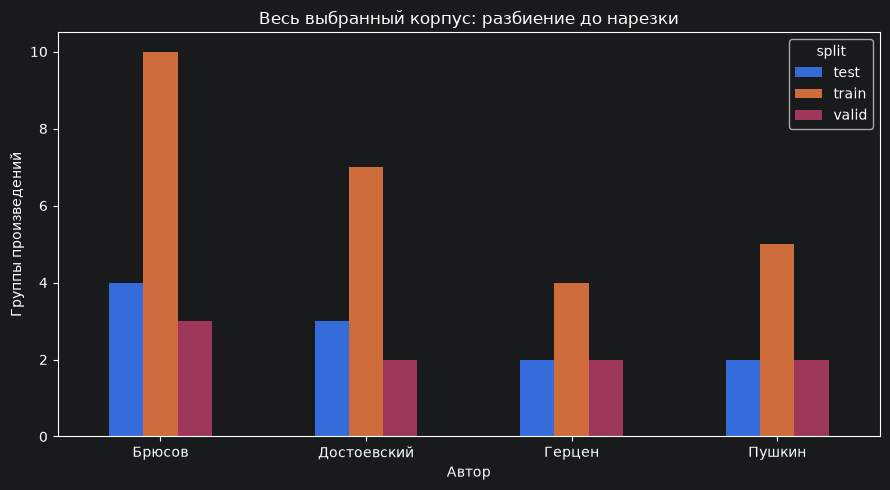

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
work_table.pivot(index="author", columns="split", values="count").rename(
    index=AUTHOR_RU
).plot.bar(ax=ax)
ax.set(
    xlabel="Автор",
    ylabel="Группы произведений",
    title="Весь выбранный корпус: разбиение до нарезки",
)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [18]:
word_tokenizer = RegexTokenizer(
    inputCol="body", outputCol="words", pattern="(?U)[^\\W_]+", gaps=False, minTokenLength=1
)
word_docs = word_tokenizer.transform(docs).withColumn("n_words", F.size("words")).cache()
assert word_docs.filter("n_words<300").count() == 0
label_map = F.create_map(
    *[x for i, a in enumerate(AUTHORS) for x in (F.lit(a), F.lit(float(i)))]
)
all_fragments = (
    word_docs.filter(F.col("role") == "classifier")
    .withColumn("start", F.explode(F.sequence(F.lit(1), F.size("words") - 299, F.lit(300))))
    .withColumn("text", F.concat_ws(" ", F.expr("slice(words,start,300)")))
    .withColumn("row_id", F.concat_ws(":", "document_id", F.col("start").cast("string")))
    .withColumn("label", label_map[F.col("author")])
    .select(
        "row_id",
        "document_id",
        "work_group",
        "title",
        "author",
        "label",
        "split",
        "start",
        "text",
    )
)
fragment_order = Window.partitionBy("work_group").orderBy(
    F.sha2(F.concat_ws(":", "row_id", F.lit(str(SEED))), 256), "row_id"
)
fragments = (
    all_fragments.withColumn("_r", F.row_number().over(fragment_order))
    .filter((F.col("split") != "train") | (F.col("_r") <= MAX_TRAIN_FRAGMENTS))
    .drop("_r")
    .cache()
)
train = fragments.filter("split='train'")
valid = fragments.filter("split='valid'")
test = fragments.filter("split='test'")

In [19]:
for part in [train, valid, test]:
    assert part.select("label").distinct().count() == K
assert (
    fragments.groupBy("work_group")
    .agg(F.countDistinct("split").alias("n"))
    .filter("n>1")
    .count()
    == 0
)
assert (
    fragments.withColumn("_h", F.sha2("text", 256))
    .groupBy("_h")
    .agg(F.countDistinct("split").alias("n"))
    .filter("n>1")
    .count()
    == 0
)
frag_table = fragments.groupBy("author", "split").count().orderBy("author", "split").toPandas()
display(frag_table.pivot(index="author", columns="split", values="count"))
frag_table.to_csv(OUT / "fragment_counts.csv", index=False)

split,test,train,valid
author,,,
Bryusov,18,158,27
Herzen,231,88,85
Pushkin,73,155,33


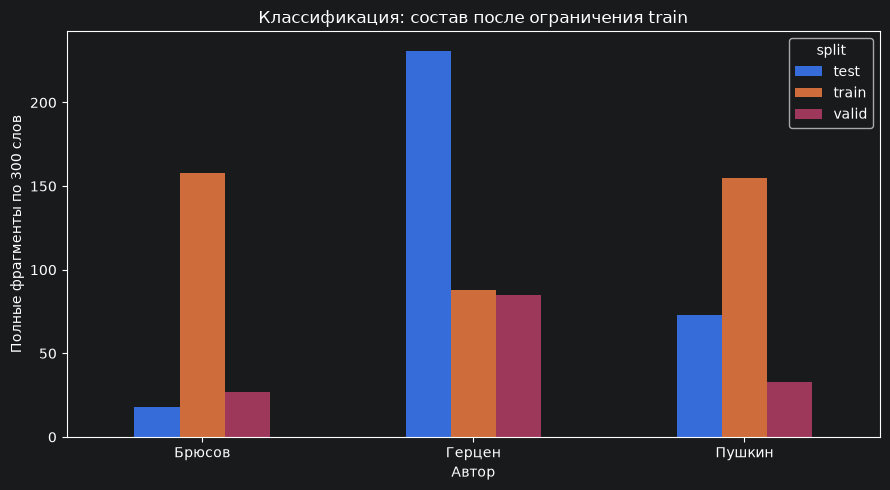

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
frag_table.pivot(index="author", columns="split", values="count").rename(
    index=AUTHOR_RU
).plot.bar(ax=ax)
ax.set(
    xlabel="Автор",
    ylabel="Полные фрагменты по 300 слов",
    title="Классификация: состав после ограничения train",
)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [21]:
passport = word_docs.select(
    "author",
    "title",
    "work_group",
    "role",
    "split",
    F.length("body").alias("body_chars"),
    "n_words",
    F.floor(F.col("n_words") / 300).cast("long").alias("full_fragments"),
    (F.col("n_words") % 300).alias("discarded_tail_words"),
).toPandas()
display(passport)
passport.to_csv(OUT / "works_report.csv", index=False)

,author,title,work_group,role,split,body_chars,n_words,full_fragments,discarded_tail_words
0,Herzen,Сорока-воровка,Herzen/Сорока-воровка,classifier,train,45556,6930,23,30
1,Herzen,Доктор Крупов,Herzen/Доктор Крупов,classifier,train,56106,8296,27,196
2,Herzen,Елена,Herzen/Елена,classifier,train,63692,9729,32,129
3,Herzen,Трагедия за стаканом грога,Herzen/Трагедия за стаканом грога,classifier,train,13627,2068,6,268
4,Herzen,Легенда,Herzen/Легенда,classifier,valid,50295,7473,24,273
5,Herzen,Долг прежде всего,Herzen/Долг прежде всего,classifier,valid,129234,18368,61,68
6,Herzen,Кто виноват,Herzen/Кто виноват,classifier,test,417134,62727,209,27
7,Herzen,Повреждённый,Herzen/Повреждённый,classifier,test,44857,6881,22,281
8,Bryusov,Сестры,Bryusov/Сестры,classifier,train,27128,4325,14,125
9,Bryusov,В зеркале,Bryusov/В зеркале,classifier,train,22304,3277,10,277


**Вывод:** Авторы представлены во всех частях. Произведения и точные фрагменты не пересекают границы выборок. Ограничение длинных произведений применяется только на train. Паспорт содержит объём основного текста, число фрагментов и отброшенный остаток каждого файла.

## 5. Частотный анализ обучающей выборки

Для классификации используется нижний регистр и слова без пунктуации. Лемматизация не применяется: словоформы могут характеризовать стиль; её эффект потребовал бы отдельного опыта. Основной вариант сохраняет служебные слова. Для сравнения используется SAFE_STOP без отрицаний и слов «но», «очень». DISPLAY_STOP скрывает фоновые токены только на графиках, не меняя основную модель.

TF - число вхождений, DF - число train-фрагментов с токеном. Доля фрагментов автора с токеном позволяет сравнить авторов разного объёма. Частотные исследования проводятся только на фактически используемом train после ограничения длинных произведений.

In [22]:
TOKEN_PATTERN = "(?U)[^\\W_]+"
RU_STOP = StopWordsRemover.loadDefaultStopWords("russian")
SAFE_STOP = sorted(set(RU_STOP) - {"не", "ни", "нет", "без", "но", "очень"})
DISPLAY_STOP = set(RU_STOP) - {"не", "нет"}

def token_stage():
    return RegexTokenizer(
        inputCol="text", outputCol="tokens", pattern=TOKEN_PATTERN, gaps=False, minTokenLength=1
    )

eda = token_stage().transform(train).cache()
occurrences = eda.select("row_id", "author", F.explode("tokens").alias("term")).cache()
stats = (
    occurrences.groupBy("term")
    .agg(F.count("*").alias("tf"), F.countDistinct("row_id").alias("df"))
    .cache()
)
top = (
    stats.filter(~F.col("term").isin(sorted(DISPLAY_STOP)))
    .orderBy(F.desc("df"), "term")
    .limit(20)
    .toPandas()
)
display(top)
top.to_csv(OUT / "train_terms.csv", index=False)

,term,tf,df
0,не,2475,398
1,это,457,246
2,сказал,251,154
3,время,154,132
4,день,152,117
5,очень,149,114
6,несколько,150,113
7,нет,163,110
8,своей,148,109
9,мог,119,97


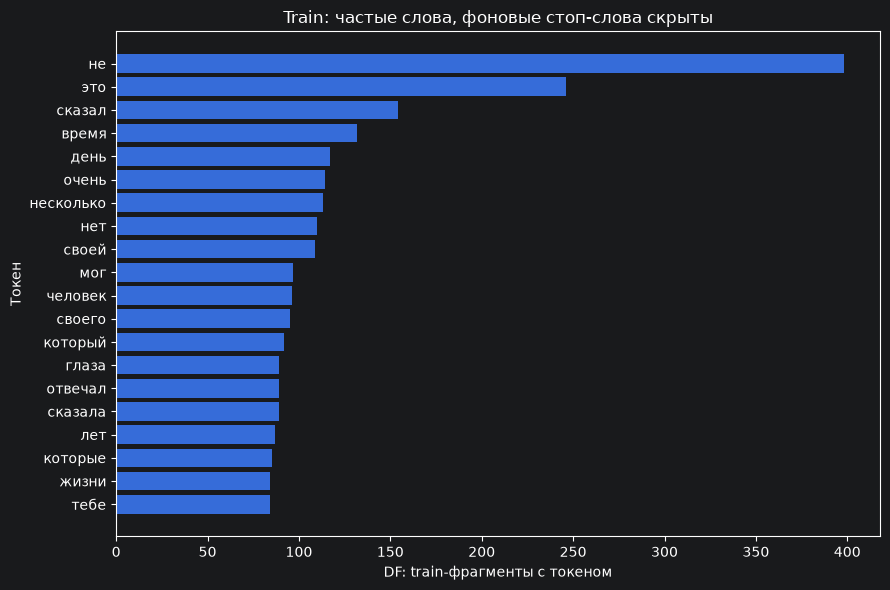

In [23]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.term[::-1], top.df[::-1])
ax.set(
    xlabel="DF: train-фрагменты с токеном",
    ylabel="Токен",
    title="Train: частые слова, фоновые стоп-слова скрыты",
)
plt.tight_layout()
plt.show()

In [24]:
ranked = stats.orderBy(F.desc("tf"), "term").limit(10000).toPandas()

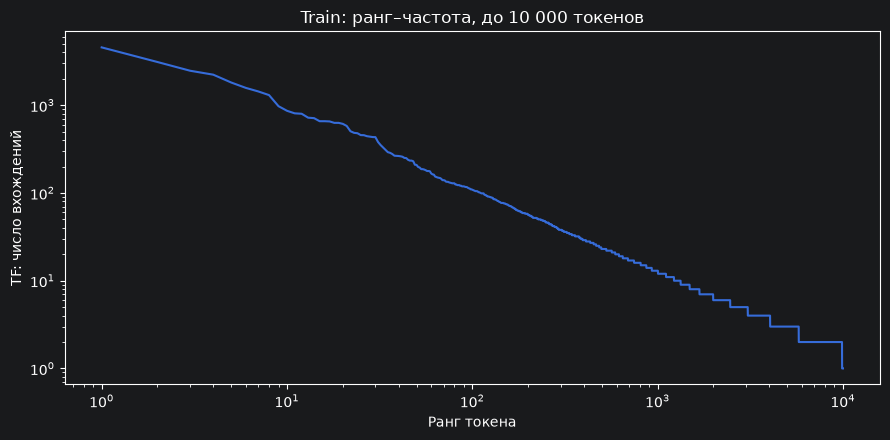

In [25]:
fig, ax = plt.subplots()
ax.loglog(np.arange(1, len(ranked) + 1), ranked.tf)
ax.set(
    xlabel="Ранг токена",
    ylabel="TF: число вхождений",
    title="Train: ранг–частота, до 10 000 токенов",
)
plt.tight_layout()
plt.show()

**Вывод:** Наибольшая показанная DF у **не**: **398** фрагментов. Частоты относятся только к train. Имена героев и сюжетная лексика могут влиять на модель, поэтому valid/test состоят из независимых произведений.

In [26]:
terms = ["я", "он", "она", "вы", "не", "мой", "сказал", "человек", "душа", "жизнь"]
class_n = eda.groupBy("author").count().withColumnRenamed("count", "n")
small = (
    occurrences.filter(F.col("term").isin(terms))
    .groupBy("term", "author")
    .agg(F.countDistinct("row_id").alias("df"))
    .join(class_n, "author")
    .withColumn("share", F.col("df") / F.col("n"))
    .select("term", "author", "share")
    .toPandas()
)
profile = (
    small.pivot(index="term", columns="author", values="share")
    .reindex(index=terms, columns=AUTHORS)
    .fillna(0)
)

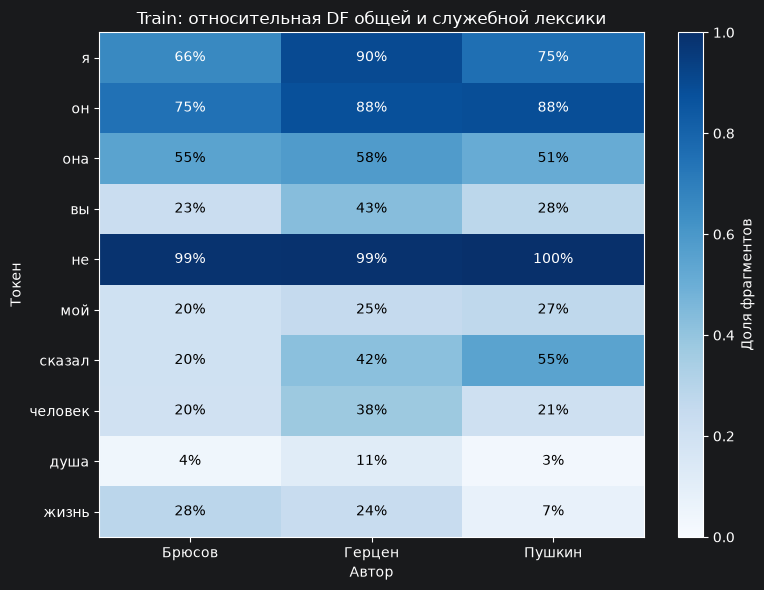

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(profile.to_numpy(), vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks(range(K), [AUTHOR_RU[a] for a in AUTHORS])
ax.set_yticks(range(len(terms)), terms)
for i in range(len(terms)):
    for j in range(K):
        ax.text(
            j,
            i,
            f"{profile.iloc[i, j]:.0%}",
            ha="center",
            va="center",
            color="white" if profile.iloc[i, j] > 0.6 else "black",
        )
ax.set(
    xlabel="Автор", ylabel="Токен", title="Train: относительная DF общей и служебной лексики"
)
fig.colorbar(im, ax=ax, label="Доля фрагментов")
plt.tight_layout()
plt.show()

In [28]:
profile.to_csv(OUT / "train_author_profile.csv")

**Вывод:** Служебные слова отражают также лицо рассказчика, долю диалогов и форму повествования. Относительная DF учитывает разное число фрагментов. Точные значения приведены в таблицах.

## 6. Bag of Words и TF–IDF

BoW хранит счётчики в координатах обученного словаря. Разреженная запись содержит размерность, индексы и значения ненулевых координат. Плотная float64-матрица N×V требует примерно 8NV байт без служебных расходов.

В Spark используется сглаженная формула:

$$IDF(t)=\ln\frac{N_{train}+1}{DF_{train}(t)+1},\qquad TFIDF(t,d)=TF(t,d)IDF(t).$$

Токен во всех train-документах получает нулевой IDF. Ненулевой вектор после L2-нормирования имеет длину 1. Учебные документы ниже не входят в авторский корпус; только эти маленькие векторы переводятся в плотный формат.

In [29]:
toy = spark.createDataFrame(
    [
        (0, "герой сказал сказал".split()),
        (1, "герой не сказал".split()),
        (2, "ночь тихая".split()),
    ],
    ["id", "tokens"],
)
vocab = ["герой", "сказал", "не", "ночь", "тихая"]
toy_counts = CountVectorizerModel.from_vocabulary(
    vocab, inputCol="tokens", outputCol="counts"
).transform(toy)
expected = np.array([[1, 2, 0, 0, 0], [1, 1, 1, 0, 0], [0, 0, 0, 1, 1]])
np.testing.assert_array_equal(
    np.array([r.counts.toArray() for r in toy_counts.orderBy("id").collect()]), expected
)
idf_toy = IDF(inputCol="counts", outputCol="tfidf").fit(toy_counts)
manual_idf = np.log(4 / (np.count_nonzero(expected, axis=0) + 1))
np.testing.assert_allclose(idf_toy.idf.toArray(), manual_idf)
manual = expected * manual_idf
manual /= np.linalg.norm(manual, axis=1, keepdims=True)
normalized = Normalizer(inputCol="tfidf", outputCol="features", p=2.0).transform(
    idf_toy.transform(toy_counts)
)
np.testing.assert_allclose(
    np.array([r.features.toArray() for r in normalized.orderBy("id").collect()]), manual
)
toy_counts.show(truncate=False)
normalized.show(truncate=False)
display(pd.DataFrame(dict(term=vocab, df=np.count_nonzero(expected, axis=0), idf=manual_idf)))
print(
    "Плотная train-матрица при V=20000 потребовала бы ГиБ:",
    round(train.count() * VOCAB_SIZE * 8 / 2**30, 3),
)
NGram(n=2, inputCol="tokens", outputCol="bigrams").transform(toy).select(
    "tokens", "bigrams"
).show(truncate=False)
HashingTF(inputCol="tokens", outputCol="hashed", numFeatures=2**16).transform(toy).select(
    "id", "hashed"
).show(truncate=False)

+---+-----------------------+-------------------------+
|id |tokens                 |counts                   |
+---+-----------------------+-------------------------+
|0  |[герой, сказал, сказал]|(5,[0,1],[1.0,2.0])      |
|1  |[герой, не, сказал]    |(5,[0,1,2],[1.0,1.0,1.0])|
|2  |[ночь, тихая]          |(5,[3,4],[1.0,1.0])      |
+---+-----------------------+-------------------------+

+---+-----------------------+-------------------------+------------------------------------------------------------------------+----------------------------------------------------------------------+
|id |tokens                 |counts                   |tfidf                                                                   |features                                                              |
+---+-----------------------+-------------------------+------------------------------------------------------------------------+----------------------------------------------------------------------+
|0  |[г

,term,df,idf
0,герой,2,0.287682
1,сказал,2,0.287682
2,не,1,0.693147
3,ночь,1,0.693147
4,тихая,1,0.693147


Плотная train-матрица при V=20000 потребовала бы ГиБ: 0.06
+-----------------------+-----------------------------+
|tokens                 |bigrams                      |
+-----------------------+-----------------------------+
|[герой, сказал, сказал]|[герой сказал, сказал сказал]|
|[герой, не, сказал]    |[герой не, не сказал]        |
|[ночь, тихая]          |[ночь тихая]                 |
+-----------------------+-----------------------------+

+---+-----------------------------------------+
|id |hashed                                   |
+---+-----------------------------------------+
|0  |(65536,[11143,55540],[2.0,1.0])          |
|1  |(65536,[11143,55540,59533],[1.0,1.0,1.0])|
|2  |(65536,[5588,6939],[1.0,1.0])            |
+---+-----------------------------------------+



**Вывод:** BoW, IDF и нормирование вручную совпали со Spark. CountVectorizer игнорирует слова вне словаря; HashingTF обрабатывает новые слова по хешу, допуская коллизии. В основном опыте выбран интерпретируемый словарь CountVectorizer.

## 7. Pipeline, baseline и метрики

| Модель | Признаки |
|---|---|
| NB_BOW | Униграммы, счётчики, все слова; multinomial NB, smoothing=1 |
| LR_BOW | Счётчики, все слова; multinomial LR, L2 |
| LR_TFIDF | TF–IDF + L2-нормирование, все слова |
| LR_TFIDF_SAFE_STOP | TF–IDF + L2, SAFE_STOP; отдельный опыт со служебными словами |

Предел словаря - 20 000, minDF=3 обучающих фрагмента. LR: regParam=0.001, standardization=False, maxIter=150. Словарь, IDF и классификатор обучаются только на train. Это сравнение фиксированных вариантов; полный подбор гиперпараметров не проводится.

Выбор модели - по **macro-F1 valid по фрагментам**. Для произведения вероятности фрагментов усредняются; ответ - автор с максимальной средней вероятностью. Произведения получают равный вес.

Строки матрицы ошибок - истинные авторы, столбцы - ответы. Precision - диагональ/сумма столбца; recall - диагональ/сумма строки; F1=2PR/(P+R). Macro-F1 даёт авторам одинаковые веса, weighted-F1 - веса по support. Встроенное Spark f1 означает weighted-F1, поэтому macro-F1 рассчитывается явно. Нулевые знаменатели дают 0. Log loss оценивает вероятность правильного автора, ограниченную снизу 10⁻¹⁵.

In [30]:
SPECS = ["NB_BOW", "LR_BOW", "LR_TFIDF", "LR_TFIDF_SAFE_STOP"]

def make_pipeline(name):
    assert name in SPECS
    stages = [token_stage()]
    inp = "tokens"
    if name.endswith("SAFE_STOP"):
        stages.append(
            StopWordsRemover(inputCol="tokens", outputCol="filtered", stopWords=SAFE_STOP)
        )
        inp = "filtered"
    use_idf = "TFIDF" in name
    stages.append(
        CountVectorizer(
            inputCol=inp,
            outputCol="counts" if use_idf else "features",
            vocabSize=VOCAB_SIZE,
            minDF=MIN_DF,
        )
    )
    if use_idf:
        stages += [
            IDF(inputCol="counts", outputCol="tfidf"),
            Normalizer(inputCol="tfidf", outputCol="features", p=2.0),
        ]
    clf = (
        NaiveBayes(modelType="multinomial", smoothing=1.0)
        if name == "NB_BOW"
        else LogisticRegression(
            family="multinomial",
            regParam=REG_PARAM,
            elasticNetParam=0.0,
            standardization=False,
            maxIter=150,
            tol=1e-06,
        )
    )
    return Pipeline(stages=stages + [clf])

In [31]:
def metrics(pred):
    cm = np.zeros((K, K), dtype=np.int64)
    for r in pred.groupBy("label", "prediction").count().collect():
        cm[int(r.label), int(r.prediction)] = r["count"]
    assert cm.sum() > 0
    support, predicted = (cm.sum(axis=1), cm.sum(axis=0))
    tp = np.diag(cm).astype(float)
    precision = np.divide(tp, predicted, out=np.zeros(K), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros(K), where=support > 0)
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(K),
        where=precision + recall > 0,
    )
    valid_metrics = dict(
        accuracy=float(tp.sum() / cm.sum()),
        macro_f1=float(f1.mean()),
        weighted_f1=float(f1 @ support / cm.sum()),
        n=int(cm.sum()),
    )
    if "probability" in pred.columns:
        scored = pred.withColumn("_p", vector_to_array("probability"))
        true_p = F.expr("element_at(_p,cast(label as int)+1)")
        valid_metrics["log_loss"] = float(
            scored.agg(F.avg(-F.log(F.greatest(true_p, F.lit(1e-15))))).first()[0]
        )
    return (
        valid_metrics,
        pd.DataFrame(
            dict(
                author=[LABEL_NAMES[i] for i in range(K)],
                support=support,
                precision=precision,
                recall=recall,
                f1=f1,
            )
        ),
        cm,
    )

In [32]:
def work_predictions(pred):
    p = pred.withColumn("_p", vector_to_array("probability"))
    p = p.groupBy("work_group", "author", "label").agg(
        *[F.avg(F.col("_p")[i]).alias(f"p{i}") for i in range(K)],
        F.count("*").alias("n_fragments"),
    )
    p = p.withColumn("_p", F.array(*[F.col(f"p{i}") for i in range(K)]))
    return (
        p.withColumn(
            "prediction", (F.expr("array_position(_p,array_max(_p))") - 1).cast("double")
        )
        .withColumn("probability", array_to_vector("_p"))
        .drop("_p")
    )

majority = float(train.groupBy("label").count().orderBy(F.desc("count"), "label").first().label)
baseline_valid, _, _ = metrics(valid.withColumn("prediction", F.lit(majority)))
print("Постоянный автор:", LABEL_NAMES[int(majority)], "| valid:", baseline_valid)

Постоянный автор: Брюсов | valid: {'accuracy': 0.18620689655172415, 'macro_f1': 0.1046511627906977, 'weighted_f1': 0.058460304731355266, 'n': 145}


## 8. Обучение и сравнение на valid

In [33]:
models = {}
validation_rows = []
validation_by_author = []
for name in SPECS:
    sc.setJobGroup("PR6_" + name, "Обучение " + name)
    started = perf_counter()
    model = make_pipeline(name).fit(train)
    fit_s = perf_counter() - started
    pred = model.transform(valid).cache()
    pred.count()
    valid_metrics, valid_by_author, _ = metrics(pred)
    valid_work_metrics, _, _ = metrics(work_predictions(pred))
    vectorizer = next((s for s in model.stages if isinstance(s, CountVectorizerModel)))
    validation_rows.append(
        dict(
            model=name,
            vocabulary=len(vectorizer.vocabulary),
            fit_s=fit_s,
            work_macro_f1=valid_work_metrics["macro_f1"],
            **valid_metrics
        )
    )
    valid_by_author["model"] = name
    validation_by_author.append(valid_by_author)
    models[name] = model
    pred.unpersist()
    print(
        name, "valid macro-F1:", round(valid_metrics["macro_f1"], 4), "fit, с:", round(fit_s, 2)
    )
comparison = (
    pd.DataFrame(validation_rows)
    .sort_values(["macro_f1", "model"], ascending=[False, True])
    .reset_index(drop=True)
)
display(comparison.round(4))
display(pd.concat(validation_by_author).round(4))
comparison.to_csv(OUT / "validation.csv", index=False)
pd.concat(validation_by_author).to_csv(OUT / "validation_by_author.csv", index=False)

NB_BOW valid macro-F1: 0.8286 fit, с: 1.1
LR_BOW valid macro-F1: 0.6746 fit, с: 28.39
LR_TFIDF valid macro-F1: 0.5887 fit, с: 30.75
LR_TFIDF_SAFE_STOP valid macro-F1: 0.5898 fit, с: 17.96


,model,vocabulary,fit_s,work_macro_f1,accuracy,macro_f1,weighted_f1,n,log_loss
0,NB_BOW,5486,1.0965,1.0000,0.8276,0.8286,0.8305,145,1.1561
1,LR_BOW,5486,28.3920,0.8222,0.6552,0.6746,0.6632,145,0.7615
2,LR_TFIDF_SAFE_STOP,5340,17.9609,0.8222,0.5724,0.5898,0.5358,145,0.9024
3,LR_TFIDF,5486,30.7549,0.5524,0.5793,0.5887,0.5427,145,0.8816


,author,support,precision,recall,f1,model
0,Брюсов,27,0.8182,1.0000,0.9000,NB_BOW
1,Герцен,85,0.9552,0.7529,0.8421,NB_BOW
2,Пушкин,33,0.6444,0.8788,0.7436,NB_BOW
0,Брюсов,27,0.7419,0.8519,0.7931,LR_BOW
1,Герцен,85,0.9348,0.5059,0.6565,LR_BOW
2,Пушкин,33,0.4265,0.8788,0.5743,LR_BOW
0,Брюсов,27,0.4909,1.0000,0.6585,LR_TFIDF
1,Герцен,85,1.0000,0.3059,0.4685,LR_TFIDF
2,Пушкин,33,0.4844,0.9394,0.6392,LR_TFIDF
0,Брюсов,27,0.5778,0.9630,0.7222,LR_TFIDF_SAFE_STOP


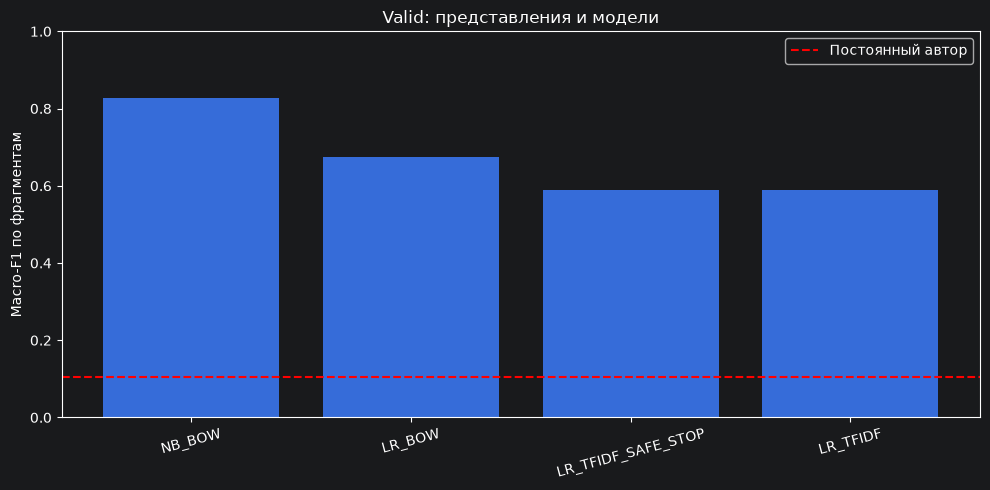

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(comparison.model, comparison.macro_f1)
ax.axhline(baseline_valid["macro_f1"], linestyle="--", color="red", label="Постоянный автор")
ax.set(ylabel="Macro-F1 по фрагментам", ylim=(0, 1), title="Valid: представления и модели")
ax.tick_params(axis="x", rotation=15)
ax.legend()
plt.tight_layout()
plt.show()

In [35]:
BEST_NAME = str(comparison.iloc[0]["model"])
BEST_MODEL = models[BEST_NAME]
stop_rows = comparison[comparison.model.isin(["LR_TFIDF", "LR_TFIDF_SAFE_STOP"])]
display(stop_rows[["model", "vocabulary", "macro_f1", "fit_s"]].round(4))
stop_winner = stop_rows.sort_values(["macro_f1", "model"], ascending=[False, True]).iloc[0]

,model,vocabulary,macro_f1,fit_s
2,LR_TFIDF_SAFE_STOP,5340,0.5898,17.9609
3,LR_TFIDF,5486,0.5887,30.7549


**Вывод:** Выбран **NB_BOW**, macro-F1 valid=0.8286. Среди вариантов служебных слов лучший - **LR_TFIDF_SAFE_STOP**. Параметры после этой точки фиксированы; вывод относится к этому корпусу и регуляризации.

## 9. Однократная оценка на test

Проверяются только выбранная модель и постоянное правило. Для других моделей в итоговой таблице тестовые показатели оставлены пустыми. Повторного обучения на train+valid нет. Число тестовых произведений каждого автора приведено рядом с метриками: при двух–четырёх группах одна ошибка существенно меняет результат.

In [36]:
test_pred = BEST_MODEL.transform(test).cache()
test_pred.count()
TEST_FRAG, TEST_CLASSES, TEST_CM = metrics(test_pred)
test_works = work_predictions(test_pred).cache()
TEST_WORK, WORK_CLASSES, WORK_CM = metrics(test_works)
BASE_FRAG, _, _ = metrics(test.withColumn("prediction", F.lit(majority)))
BASE_WORK, _, _ = metrics(
    test.select("work_group", "author", "label")
    .distinct()
    .withColumn("prediction", F.lit(majority))
)
summary_test = pd.DataFrame(
    [
        dict(model=BEST_NAME, level="fragment", **TEST_FRAG),
        dict(model=BEST_NAME, level="work", **TEST_WORK),
        dict(model="majority", level="fragment", **BASE_FRAG),
        dict(model="majority", level="work", **BASE_WORK),
    ]
)
display(summary_test.round(4))
display(TEST_CLASSES.round(4))
display(WORK_CLASSES.round(4))
summary_test.to_csv(OUT / "test_metrics.csv", index=False)
TEST_CLASSES.to_csv(OUT / "test_fragment_by_author.csv", index=False)
WORK_CLASSES.to_csv(OUT / "test_work_by_author.csv", index=False)
final_comparison = (
    comparison[["model", "macro_f1", "fit_s"]]
    .rename(columns={"macro_f1": "valid_macro_f1"})
    .copy()
)
final_comparison["test_fragment_macro_f1"] = np.nan
final_comparison["test_work_macro_f1"] = np.nan
final_comparison.loc[
    final_comparison.model == BEST_NAME, ["test_fragment_macro_f1", "test_work_macro_f1"]
] = [TEST_FRAG["macro_f1"], TEST_WORK["macro_f1"]]

,model,level,accuracy,macro_f1,weighted_f1,n,log_loss
0,NB_BOW,fragment,0.8478,0.7772,0.8579,322,1.0535
1,NB_BOW,work,1.0000,1.0000,1.0000,8,0.0629
2,majority,fragment,0.0559,0.0353,0.0059,322,NaN
3,majority,work,0.5000,0.2222,0.3333,8,NaN


,author,support,precision,recall,f1
0,Брюсов,18,0.4474,0.9444,0.6071
1,Герцен,231,0.9892,0.7965,0.8825
2,Пушкин,73,0.7347,0.9863,0.8421


,author,support,precision,recall,f1
0,Брюсов,4,1.0,1.0,1.0
1,Герцен,2,1.0,1.0,1.0
2,Пушкин,2,1.0,1.0,1.0


In [37]:
final_comparison = pd.concat(
    [
        pd.DataFrame(
            [
                dict(
                    model="majority",
                    valid_macro_f1=baseline_valid["macro_f1"],
                    fit_s=0.0,
                    test_fragment_macro_f1=BASE_FRAG["macro_f1"],
                    test_work_macro_f1=BASE_WORK["macro_f1"],
                )
            ]
        ),
        final_comparison,
    ],
    ignore_index=True,
)
display(final_comparison.fillna("-"))
final_comparison.to_csv(OUT / "final_comparison.csv", index=False)
cm = TEST_CM
normalized_cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

,model,valid_macro_f1,fit_s,test_fragment_macro_f1,test_work_macro_f1
0,majority,0.104651,0.000000,0.035294,0.222222
1,NB_BOW,0.828565,1.096455,0.777247,1.0
2,LR_BOW,0.674616,28.392035,-,-
3,LR_TFIDF_SAFE_STOP,0.589787,17.960897,-,-
4,LR_TFIDF,0.588727,30.754917,-,-


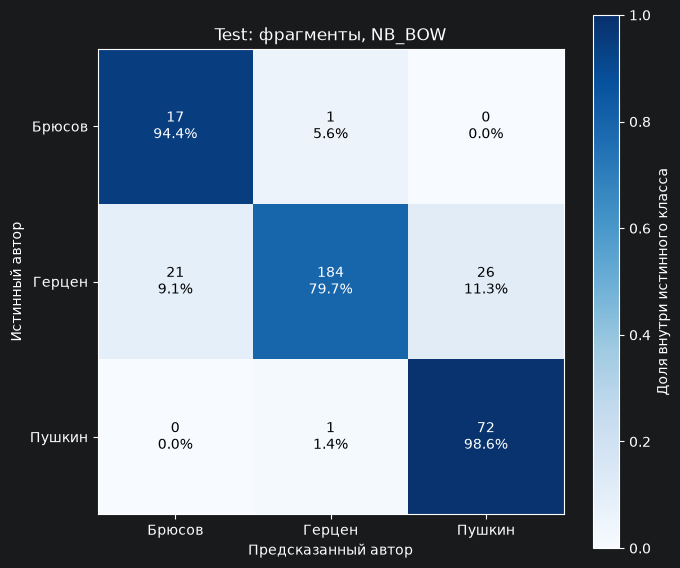

In [38]:
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(normalized_cm, vmin=0, vmax=1, cmap="Blues")
for true_author in range(K):
    for predicted_author in range(K):
        share = normalized_cm[true_author, predicted_author]
        ax.text(
            predicted_author,
            true_author,
            f"{cm[true_author, predicted_author]}\n{share:.1%}",
            ha="center",
            va="center",
            color="white" if share > 0.6 else "black",
        )
author_names = [LABEL_NAMES[i] for i in range(K)]
ax.set_xticks(range(K), author_names)
ax.set_yticks(range(K), author_names)
ax.set(
    xlabel="Предсказанный автор", ylabel="Истинный автор", title=f"Test: фрагменты, {BEST_NAME}"
)
fig.colorbar(image, ax=ax, label="Доля внутри истинного класса")
plt.tight_layout()
plt.show()

In [39]:
cm = WORK_CM
normalized_cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

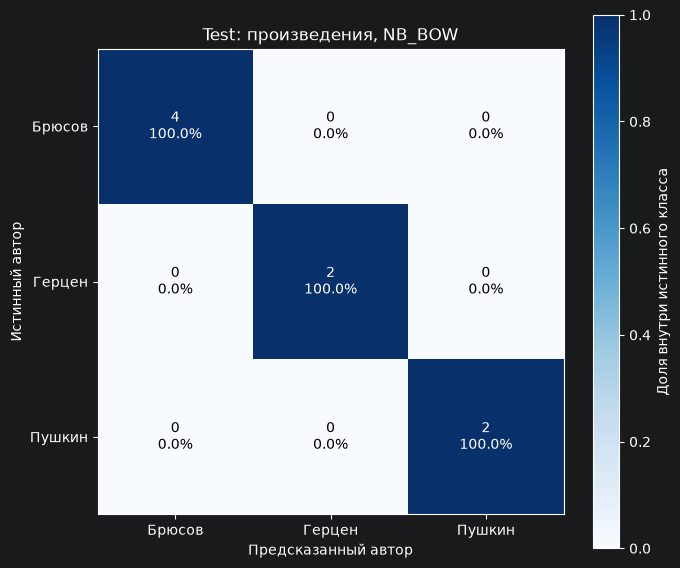

In [40]:
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(normalized_cm, vmin=0, vmax=1, cmap="Blues")
for true_author in range(K):
    for predicted_author in range(K):
        share = normalized_cm[true_author, predicted_author]
        ax.text(
            predicted_author,
            true_author,
            f"{cm[true_author, predicted_author]}\n{share:.1%}",
            ha="center",
            va="center",
            color="white" if share > 0.6 else "black",
        )
author_names = [LABEL_NAMES[i] for i in range(K)]
ax.set_xticks(range(K), author_names)
ax.set_yticks(range(K), author_names)
ax.set(
    xlabel="Предсказанный автор",
    ylabel="Истинный автор",
    title=f"Test: произведения, {BEST_NAME}",
)
fig.colorbar(image, ax=ax, label="Доля внутри истинного класса")
plt.tight_layout()
plt.show()

**Вывод:** Test по фрагментам: macro-F1 **0.7772**, accuracy **0.8478**. Все фрагменты получены из целиком отложенных произведений. Test по произведениям: macro-F1 **1.0000** на **8** группах. Support в WORK_CLASSES - число тестовых произведений автора; каждая группа имеет равный вес.

## 10. Покрытие словаря и разбор ошибок

OOV - доля вхождений вне обученного словаря после выбранной предобработки. nnz - число ненулевых координат готового вектора; известный токен может занулиться из-за IDF. Покрытие измеряется без переобучения словаря на valid/test.

Выводятся до десяти ошибок, по возможности из разных произведений: текст, метки, обе вероятности, OOV и идентификатор. Пять и более ошибок разбираются при их наличии; вымышленные примеры не добавляются. После просмотра ошибок параметры не изменяются.

In [41]:
cv_best = next((s for s in BEST_MODEL.stages if isinstance(s, CountVectorizerModel)))
terms_col = cv_best.getInputCol()
vocab_set = set(cv_best.vocabulary)
vocab_df = spark.createDataFrame([(s,) for s in cv_best.vocabulary], ["term"])

@F.udf(T.IntegerType())
def nnz(v):
    return int(v.numNonzeros())

coverage_rows = []
for split_name, part in [("train", train), ("valid", valid), ("test", test)]:
    pred = BEST_MODEL.transform(part).cache()
    all_terms = pred.select(F.explode(terms_col).alias("term"))
    total = all_terms.count()
    oov = all_terms.join(F.broadcast(vocab_df), "term", "left_anti").count()
    cov = pred.withColumn("_nnz", nnz("features"))
    row = cov.agg(
        F.sum((F.col("_nnz") == 0).cast("long")).alias("zero"), F.avg("_nnz").alias("mean_nnz")
    ).first()
    coverage_rows.append(
        dict(
            split=split_name,
            terms=total,
            oov_share=oov / max(total, 1),
            zero_vectors=int(row.zero),
            mean_nnz=float(row.mean_nnz),
        )
    )
    pred.unpersist()
coverage_table = pd.DataFrame(coverage_rows)
display(coverage_table.round(4))
coverage_table.to_csv(OUT / "coverage.csv", index=False)
test_pred.withColumn("_nnz", nnz("features")).filter("_nnz=0").select(
    "work_group", "text"
).show(3, truncate=100)
err = test_pred.filter(F.col("label") != F.col("prediction")).withColumn(
    "_p", vector_to_array("probability")
)
err = err.withColumn("confidence", F.array_max("_p")).withColumn(
    "true_probability", F.expr("element_at(_p,cast(label as int)+1)")
)
error_order = Window.partitionBy("work_group").orderBy(F.desc("confidence"), "row_id")

,split,terms,oov_share,zero_vectors,mean_nnz
0,train,120300,0.2187,0,152.4115
1,valid,43500,0.3223,0,130.6276
2,test,96600,0.2919,0,134.2702


+----------+----+
|work_group|text|
+----------+----+
+----------+----+



In [42]:
errors = (
    err.withColumn("_r", F.row_number().over(error_order))
    .orderBy("_r", F.desc("confidence"), "row_id")
    .select(
        "row_id",
        "work_group",
        "author",
        "title",
        "text",
        "label",
        "prediction",
        "confidence",
        "true_probability",
        terms_col,
    )
    .limit(10)
    .toPandas()
)

In [43]:
if len(errors):
    errors["true_author"] = errors.label.astype(int).map(LABEL_NAMES)
    errors["predicted_author"] = errors.prediction.astype(int).map(LABEL_NAMES)
    errors["oov_share"] = [
        sum((w not in vocab_set for w in terms)) / max(len(terms), 1)
        for terms in errors[terms_col]
    ]
    display(
        errors[
            [
                "row_id",
                "title",
                "true_author",
                "predicted_author",
                "confidence",
                "true_probability",
                "oov_share",
            ]
        ]
    )
    for r in errors.itertuples():
        print("\n", r.row_id, "|", r.title, "|", r.true_author, "->", r.predicted_author)
        print(
            "p(прогноз)=",
            round(r.confidence, 4),
            "p(метка)=",
            round(r.true_probability, 4),
            "OOV=",
            round(r.oov_share, 4),
        )
        print(r.text)
    errors.drop(columns=[terms_col]).to_csv(OUT / "error_examples.csv", index=False)
else:
    print("Ошибок не обнаружено; вымышленные примеры не добавляются.")

,row_id,title,true_author,predicted_author,confidence,true_probability,oov_share
0,eb2a719dea2c94b66cfba5227bdd759bcdfc7f6889bdd8...,Кто виноват,Герцен,Пушкин,1.000000,1.787716e-08,0.310000
1,51948ef4f3f18edc047ed4ed64fb1aa4c8ce7db84b7888...,Дубровский,Пушкин,Герцен,0.999924,7.550937e-05,0.230000
2,72db0a337287ae0045af40dbdfa79105cee1019c6b35aa...,Повреждённый,Герцен,Брюсов,0.837121,1.628791e-01,0.273333
3,c0465652d79a1ec60abcb76a48f145345e5042593afe08...,Мраморная головка,Брюсов,Герцен,0.708558,2.914420e-01,0.140000
4,eb2a719dea2c94b66cfba5227bdd759bcdfc7f6889bdd8...,Кто виноват,Герцен,Пушкин,1.000000,2.533072e-08,0.326667
5,eb2a719dea2c94b66cfba5227bdd759bcdfc7f6889bdd8...,Кто виноват,Герцен,Пушкин,1.000000,3.206740e-08,0.330000
6,eb2a719dea2c94b66cfba5227bdd759bcdfc7f6889bdd8...,Кто виноват,Герцен,Пушкин,1.000000,5.234910e-08,0.276667
7,eb2a719dea2c94b66cfba5227bdd759bcdfc7f6889bdd8...,Кто виноват,Герцен,Пушкин,1.000000,8.615053e-08,0.293333
8,eb2a719dea2c94b66cfba5227bdd759bcdfc7f6889bdd8...,Кто виноват,Герцен,Пушкин,0.999998,2.009240e-06,0.413333
9,eb2a719dea2c94b66cfba5227bdd759bcdfc7f6889bdd8...,Кто виноват,Герцен,Пушкин,0.999998,2.145896e-06,0.266667



 eb2a719dea2c94b66cfba5227bdd759bcdfc7f6889bdd8912216597a73f684b2:24901 | Кто виноват | Герцен -> Пушкин
p(прогноз)= 1.0 p(метка)= 0.0 OOV= 0.31
хотели обогнать вы знаете сердце русского поручик закричал кучеру пошел пошел закричал львиным голосом высокий статный мужчина закутанный в медвежью шубу и сидевший в других санях поручик обогнал задыхаясь от бешенства при повороте господин в медвежьей шубе державший в руке арапник вытянул им поручичьего кучера нарочно зацепив за барина не перегонять бестия что вы с ума сошли спросил офицер я хочу отучить вашего дурака чтоб он не смел перегонять я ему велел скакать милостивый государь и вы понимаете что я слишком уважаю мундир моей государыни чтоб позволить запятнать его ба какой молодчик да кто ты такой да ты кто спросил поручик готовый броситься на него как зверь статный мужчина посмотрел на него с презрением показал ему свой кулак величиною о слоновью ногу и сказал в рукопашный нет брат отстанешь потом закричал кучеру пошел ступай за ним в

**Вывод:** Отобрано 10 ошибок для содержательного разбора. Вероятности и OOV помогают отделить недостаток словаря от ошибок на известных словах. Лексика героев, тема произведения и доля диалогов могут влиять сильнее устойчивого авторского стиля.

### Содержательный разбор пяти ошибок контрольного расчёта

Разбор привязан к идентификаторам сохранённого запуска. Причины сформулированы как гипотезы по содержанию; вклад конкретного слова отдельно не измерялся. После чтения ошибок классификатор и его параметры не менялись.

| Произведение и начало фрагмента | Исходный автор -> ответ | OOV / p ответа | Разбор                                                                                                                                                                                                                                                                                                                                                                                                                       |
|---|---|---|------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Кто виноват, слово № 24901 | Герцен -> Пушкин | 31.0% / 1.0000 | Фрагмент рассказывает об офицере, генерале, гвардии, крепости и помещике. В train Пушкина есть «Капитанская дочка» и «Арап Петра Великого»: такая тематическая и сословная лексика может поддерживать ошибочную ассоциацию с Пушкиным. OOV заметен, но большинство токенов известно. Вероятность почти 1 при ошибке показывает избыточную уверенность NB, а не надёжную атрибуцию.                                           |
| Дубровский, слово № 16801 | Пушкин -> Герцен | 23.0% / 0.9999 | Романтический диалог о принудительном браке содержит общие слова о любви, судьбе, душе и семейном расчёте. Эта тема встречается у разных авторов и не даёт однозначного стилевого признака. Имя Дубровского присутствует, однако этого недостаточно для правильного ответа: произведение целиком отложено, и имя могло отсутствовать в train-словаре. Важно не подменять проверку авторства угадыванием известного названия. |
| Повреждённый, слово № 1 | Герцен -> Брюсов | 27.3% / 0.8371 | Повествование от первого лица, образы мистики и размышления о душевной боли сближают этот отрывок с психологическими рассказами Брюсова, присутствующими в train. Это содержательная гипотеза по тексту, а не доказательство вклада отдельных признаков. Потеря порядка слов в BoW ограничивает распознавание синтаксического рисунка.                                                                                       |
| Мраморная головка, слово № 301 | Брюсов -> Герцен | 14.0% / 0.7086 | Рассказчик от первого лица рассуждает о забывании любви, карьере, бедности и жизни. В train Герцена есть повествовательные и рефлексивные тексты, поэтому сюжетно-речевая форма могла перевесить особенности Брюсова. Доля OOV ниже, чем в ряде других ошибок: модель ошибается и при достаточно хорошем покрытии словаря.                                                                                                   |
| Кто виноват, слово № 601 | Герцен -> Пушкин | 32.7% / 1.0000 | Разговор помещика с учителем и семейная бытовая сцена используют общую лексику дворянской прозы. «Алексей», обращения и социальные обозначения могут связываться у модели с пушкинским train-корпусом; специфические слова и искажения частично оказываются OOV. Два разных отрывка «Кто виноват?» демонстрируют повторяющуюся путаницу, но всё произведение после усреднения вероятностей распознано верно.                 |

Высокая уверенность NB в ошибках согласуется с ограничением условной независимости слов: связанные токены и повторяющаяся лексика могут усиливать оценку слишком резко. Поэтому рядом с F1 приведён log loss, а максимум probability не считается гарантией верного авторства.

Из 322 тестовых фрагментов 231 относится к Герцену. У каждого произведения много зависимых фрагментов; это не 322 независимые книги. На уровне произведений тест содержит 4 группы Брюсова, 2 Герцена и 2 Пушкина. Правильные ответы на все восемь групп дают F1=1, но не доказывают безошибочность на новых произведениях.

## 11. Различающие слова авторов

In [44]:
lr_pipe = models["LR_TFIDF"]
lr_cv = next((s for s in lr_pipe.stages if isinstance(s, CountVectorizerModel)))
weights = lr_pipe.stages[-1].coefficientMatrix.toArray()
contrast = weights[AUTHORS.index("Herzen")] - weights[AUTHORS.index("Pushkin")]
idx = np.unique(np.r_[np.argsort(contrast)[:12], np.argsort(contrast)[-12:]])
coef_table = pd.DataFrame(
    {"term": np.array(lr_cv.vocabulary)[idx], "contrast": contrast[idx]}
).sort_values("contrast")
display(coef_table)
coef_table.to_csv(OUT / "coefficient_contrast.csv", index=False)

,term,contrast
8,марья,-1.596053
16,графиня,-1.556038
6,петр,-1.526272
12,алексей,-1.481585
7,ибрагим,-1.450144
18,чарский,-1.375398
19,ибрагима,-1.295713
15,савельич,-1.293813
4,батюшка,-1.275246
11,лиза,-1.211372


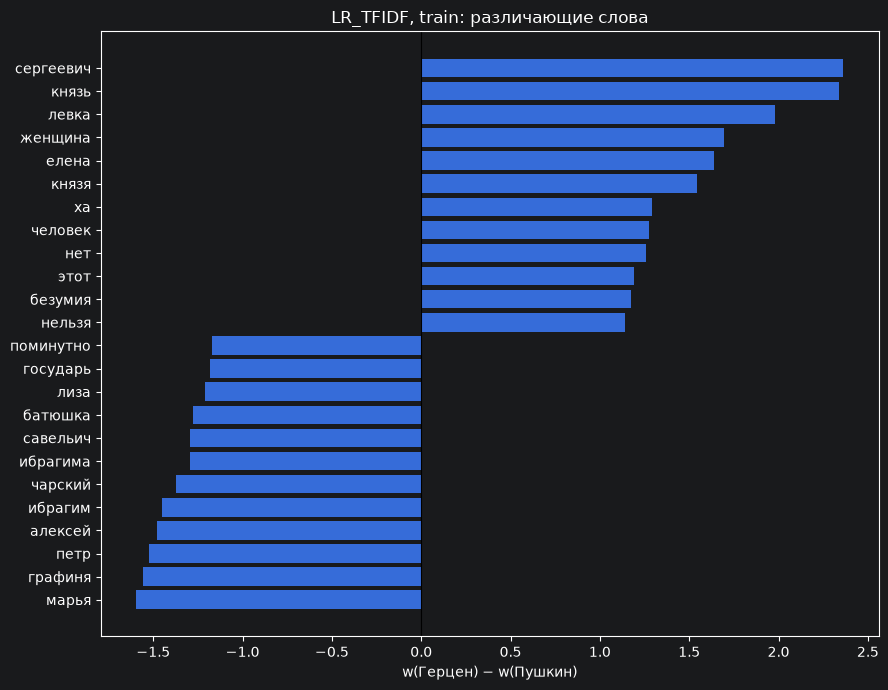

In [45]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(coef_table.term, coef_table.contrast)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="w(Герцен) − w(Пушкин)", title="LR_TFIDF, train: различающие слова")
plt.tight_layout()
plt.show()

**Вывод:** Коэффициенты относятся к выбранным произведениям и масштабу признаков. Имена и темы могут хуже переноситься на новую книгу, чем общая речевая статистика; однако даже служебные слова зависят от формы повествования.

### Что показывают слова в выполненном запуске

Со стороны Пушкина выделяются «ибрагим», «чарский», «савельич», «государь»; со стороны Герцена - «сергеевич», «елена», «левка», «князь», «женщина». Здесь значительная часть контраста связана с персонажами и социальным окружением конкретных train-произведений, а не только с авторским синтаксисом. Например, «Ибрагим» и «Чарский» относятся к выбранной прозе Пушкина. Заглавия и начальные имена авторов удалены, однако имена персонажей внутри основного текста сохранены.

Служебные «этот», «нет», «нельзя» также вошли в положительную сторону контраста. Они потенциально отражают способ повествования, но их частоты могут зависеть от доли диалогов и темы книги. Делать универсальное заключение о стиле трёх авторов по этой небольшой подборке нельзя.

## 12. Подготовка train-предложений Достоевского

Генератор использует основной текст train-произведений Достоевского с сохранением словоформ, служебных слов и основной пунктуации.

В TXT встречается перенос строк по ширине: одиночные переводы склеиваются внутри абзаца, пустые строки сохраняют границу. Затем текст делится по пробелу после .?! либо по абзацам. Это эвристика: инициалы, сокращения и многоточия могут обрабатываться неточно. Произведения не соединяются.

Из предложений длиной 3–80 токенов по устойчивому хешу выбирается не более 200 на train-произведение. Лимит задан заранее для размещения таблиц на драйвере; исходный отбор и количество предложений сохраняются. Valid/test-произведения Достоевского не участвуют.

In [47]:
MARKOV_PATTERN = (
    r"[а-яёa-z0-9]+(?:[-\u2019'][а-яёa-z0-9]+)*"
    r"|[-.,!?;:\u2014]|[()]{2,}"
)

@F.udf(T.StringType())
def unwrap_lines(text):
    return "\n\n".join(
        (re.sub("\\s+", " ", p).strip() for p in re.split("\\n\\s*\\n", text) if p.strip())
    )

gen_docs = docs.filter((F.col("author") == GEN_AUTHOR) & (F.col("split") == "train")).select(
    "document_id", "work_group", "body"
)
assert gen_docs.count() > 0
assert (
    gen_docs.select("work_group")
    .distinct()
    .join(units.filter(F.col("split") != "train").select("work_group"), "work_group", "inner")
    .count()
    == 0
)
sentences = gen_docs.withColumn("paragraphs", unwrap_lines("body")).select(
    "document_id",
    "work_group",
    F.posexplode(F.split("paragraphs", "(?<=[.!?])\\s+|[\\r\\n]+")).alias(
        "sentence_id", "sentence"
    ),
)
sentences = RegexTokenizer(
    inputCol="sentence", outputCol="words", pattern=MARKOV_PATTERN, gaps=False, minTokenLength=1
).transform(sentences)
sentences = sentences.filter((F.size("words") >= 3) & (F.size("words") <= 80))
N_ELIGIBLE = sentences.count()
sentence_order = Window.partitionBy("work_group").orderBy(
    F.sha2(F.concat_ws(":", "sentence", F.lit(str(SEED))), 256), "document_id", "sentence_id"
)
sentences = (
    sentences.withColumn("_r", F.row_number().over(sentence_order))
    .filter(F.col("_r") <= GEN_SENTENCES_PER_WORK)
    .drop("_r")
    .cache()
)
N_SENTENCES = sentences.count()
assert N_SENTENCES > 0
sentences.select("document_id", "work_group", "sentence_id", "sentence").write.mode(
    "overwrite"
).parquet((OUT / "generation_sentence_manifest").as_posix())
sentences.groupBy("work_group").count().orderBy("work_group").show(truncate=False)

sentences.select("sentence", "words").show(3, truncate=140)

+------------------------------+-----+
|work_group                    |count|
+------------------------------+-----+
|Dostoevsky/Белые ночи         |200  |
|Dostoevsky/Вечный муж         |200  |
|Dostoevsky/Дядюшкин сон       |200  |
|Dostoevsky/Записки из подполья|200  |
|Dostoevsky/Игрок              |200  |
|Dostoevsky/Неточка Незванова  |200  |
|Dostoevsky/Слабое сердце      |200  |
+------------------------------+-----+

+--------------------------------------------------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------+
|                                                                                                                                    sentence|                                                                                                                                       words|
+-

**Вывод:** выбрано 1,400 предложений. Словоформы и пунктуация сохранены, источники ограничены одинаковым числом предложений.

### Переходы двух порядков

Порядок 1 использует последний токен, порядок 2 - упорядоченную пару. Перед предложением ставятся q маркеров BOS, после - EOS. Spark NGram строит биграммы для первого порядка и триграммы для второго. Переходы считаются внутри каждого предложения.

$$P(w\mid h)=\frac{c(h,w)}{\sum_u c(h,u)}.$$

В Python передаются только таблицы, прошедшие проверку лимита в 200 000 переходов. Полные таблицы счётчиков и вероятностей сохраняются в Parquet.

In [48]:
def count_transitions(sentence_df, order):
    assert order in (1, 2)
    padded = sentence_df.withColumn(
        "seq",
        F.concat(
            F.array(*[F.lit("<BOS>") for _ in range(order)]),
            F.col("words"),
            F.array(F.lit("<EOS>")),
        ),
    )
    grams = NGram(n=order + 1, inputCol="seq", outputCol="grams").transform(padded)
    parts = F.split("gram", " ")
    return (
        grams.select(F.explode("grams").alias("gram"))
        .select(
            F.lit(order).alias("order"),
            F.concat_ws(" ", F.slice(parts, 1, order)).alias("context"),
            F.element_at(parts, order + 1).alias("next"),
        )
        .groupBy("order", "context", "next")
        .count()
    )

In [49]:
transitions = (
    count_transitions(sentences, 1).unionByName(count_transitions(sentences, 2)).cache()
)
structure = (
    transitions.groupBy("order")
    .agg(F.countDistinct("context").alias("states"), F.count("*").alias("edges"))
    .orderBy("order")
    .toPandas()
)
display(structure)
structure.to_csv(OUT / "markov_structure.csv", index=False)
transitions.write.mode("overwrite").parquet((OUT / "markov_counts").as_posix())
assert (
    transitions.limit(MAX_EDGES + 1).count() <= MAX_EDGES
), "Превышен лимит драйвера: требуется явно изменить размер генеративной подвыборки"
edge_rows = [r.asDict() for r in transitions.collect()]
(OUT / "markov_counts.json").write_text(
    json.dumps(edge_rows, ensure_ascii=False), encoding="utf-8"
)
prob_edges = transitions.withColumn(
    "probability", F.col("count") / F.sum("count").over(Window.partitionBy("order", "context"))
)
assert (
    prob_edges.groupBy("order", "context")
    .agg(F.sum("probability").alias("s"))
    .filter(F.abs(F.col("s") - 1) > 1e-10)
    .count()
    == 0
)
assert (
    transitions.filter(F.col("context").contains("<EOS>") | (F.col("next") == "<BOS>")).count()
    == 0
)
prob_edges.write.mode("overwrite").parquet((OUT / "markov_probabilities").as_posix())

,order,states,edges
0,1,5702,15942
1,2,15938,21483


**Вывод:** Переходы подсчитаны средствами Spark. Вероятности в каждом состоянии суммируются в 1. EOS не имеет исходящих переходов; таблица второго порядка описывает более подробный контекст.

## 13. Генерация и проверка цепей Маркова

Варианты продолжений сортируются, затем выбираются через отдельный random.Random(seed). Температура T>0 задаёт веса exp(log(count)/T) с вычитанием максимума. T<1 усиливает частые переходы, T>1 выравнивает распределение.

Неизвестная пара второго порядка вызывает переход к одному последнему слову; неизвестное слово - к стартовому состоянию. Программа возвращает число новых токенов, длину префикса, backoff и причину остановки. Лимит относится к новым токенам.

In [50]:
def build_chain(records):
    result = defaultdict(list)
    for r in records:
        result[int(r["order"]), tuple(r["context"].split(" "))].append(
            (r["next"], int(r["count"]))
        )
    return {k: sorted(v) for k, v in result.items()}

def generate(chain, prompt="", order=2, max_tokens=40, seed=42, temperature=1.0):
    if (
        order not in (1, 2)
        or max_tokens < 1
        or (not math.isfinite(temperature))
        or (temperature <= 0)
    ):
        raise ValueError("Некорректные параметры")
    rng = random.Random(seed)
    prefix = re.findall(MARKOV_PATTERN, prompt.lower())
    history = ["<BOS>"] * order + prefix
    output = []
    backoffs = 0
    reason = "max_tokens"
    for _ in range(max_tokens):
        options = chain.get((order, tuple(history[-order:])))
        if not options and order == 2:
            options = chain.get((1, (history[-1],)))
            backoffs += 1
        if not options:
            options = chain.get((order, ("<BOS>",) * order))
            backoffs += 1
        if not options:
            raise ValueError("Нет стартового состояния")
        words, counts = zip(*options)
        logs = [math.log(c) / temperature for c in counts]
        mx = max(logs)
        word = rng.choices(words, weights=[math.exp(v - mx) for v in logs], k=1)[0]
        if word == "<EOS>":
            reason = "eos"
            break
        output.append(word)
        history.append(word)
    text = re.sub("\\s+([.,!?;:])", "\\1", " ".join(prefix + output))
    return dict(
        text=text,
        prefix_tokens=len(prefix),
        generated_tokens=len(output),
        backoffs=backoffs,
        stopped_by=reason,
    )

In [51]:
chain = build_chain(edge_rows)
generations = [
    dict(order=q, seed=s, **generate(chain, order=q, seed=s))
    for q in (1, 2)
    for s in (7, 42, 101)
]
generation_table = pd.DataFrame(generations)
display(generation_table)
for r in generations:
    print("\nПорядок", r["order"], "seed", r["seed"], ":", r["text"])
generation_table.to_csv(OUT / "generation_examples.csv", index=False)
training_sentences = sentences.select(F.concat_ws(" ", "words").alias("canonical")).distinct()
generated = spark.createDataFrame(
    [
        (r["order"], r["seed"], " ".join(re.findall(MARKOV_PATTERN, r["text"])))
        for r in generations
    ],
    ["order", "seed", "canonical"],
)
MATCHED = generated.join(training_sentences, "canonical", "left_semi").count()

,order,seed,text,prefix_tokens,generated_tokens,backoffs,stopped_by
0,1,7,зина.,0,2,0,eos
1,1,42,"послушайте, и дико на пружинах..",0,8,0,eos
2,1,101,"она бросалась меня тоже есть о, если в смятени...",0,40,0,max_tokens
3,2,7,зина взглянула на мать насмешливо и с недоумен...,0,40,0,max_tokens
4,2,42,"послушайте, зачем же это вы так, как будто заб...",0,40,0,max_tokens
5,2,101,"она вздрогнула, как мистер астлей разглядывал ...",0,18,0,eos



Порядок 1 seed 7 : зина.

Порядок 1 seed 42 : послушайте, и дико на пружинах..

Порядок 1 seed 101 : она бросалась меня тоже есть о, если в смятении куриного сердца, действительно, то городская почта, потому что вы меня в губернии, расина, что как есть к ней никакой болезни пальчик; мало простоты,

Порядок 2 seed 7 : зина взглянула на мать насмешливо и с недоумением осматривал я свои зеленые, закоптелые стены, потолок, завешанный паутиной, которую с большим успехом разводила матрена, пересматривал всю свою мебель, осматривал каждый стул, думая, не

Порядок 2 seed 42 : послушайте, зачем же это вы так, как будто забитым и даже бросилась его обнимать; дело обошлось так, помолчал еще немного вельчанинов, извиняюсь перед вами обязанным, то и па-а-анудило, что этак не всякий решится

Порядок 2 seed 101 : она вздрогнула, как мистер астлей разглядывал m-lle blanche называется m-me la comtesse; что не бьет.


**Вывод:** Получены шесть текстов для порядков 1/2 при seed=7,42,101. Точных совпадений с выбранными train-предложениями - 0/6. Более длинный контекст способен лучше сохранять сочетания и одновременно воспроизводить исходные фразы. Проверка точного совпадения не исключает частичное заимствование.

### Разбор шести сгенерированных текстов

| Порядок / seed | Наблюдение | Длина и остановка |
|---|---|---|
| 1 / 7 | Получилось только имя Зины и точка: цепь быстро пришла к границе предложения. | 2 токена, EOS |
| 1 / 42 | Несогласованное сочетание обращения, характеристики и предмета. Одного предыдущего токена недостаточно для грамматического управления. | 8 токенов, EOS |
| 1 / 101 | Смешаны обращения, душевное состояние, почта, география и другие предметы. Смена тем происходит без общего замысла. | 40 токенов, лимит |
| 2 / 7 | Начало содержит действие Зины, затем меняется лицо повествования и появляется описание комнаты. Локальные сочетания связнее, единый рассказчик не сохраняется. | 40 токенов, лимит |
| 2 / 42 | Внутри одной фразы соединены диалог, объятия, реплика Вельчанинова и новые объяснения. Узнаваемые сочетания не складываются в цельное событие. | 40 токенов, лимит |
| 2 / 101 | За началом с женским персонажем следует другая ситуация с мистером Астлеем и французскими именованиями. Фраза завершена, но синтаксически и сюжетно неоднородна. | 18 токенов, EOS |

Во втором порядке средняя длина здесь выше, но длина не является самостоятельной метрикой качества. Сохранение двухсловного контекста улучшает некоторые локальные сочетания, не обеспечивая связность на уровне нескольких предложений. Во всех шести примерах backoff=0: генерация без префикса идёт по известным состояниям. Неизвестный контекст и переход к короткому состоянию проверены отдельно ниже. Имена персонажей и иностранные реплики допустимы для исходной прозы; их случайное объединение показывает ограниченность модели.

In [52]:
known = next((h for q, h in sorted(chain) if q == 2 and "<BOS>" not in h))
print("Известный контекст:", known, generate(chain, prompt=" ".join(known), order=2))
unknown_result = generate(chain, prompt="абракадабратокен несуществующийконтекст", order=2)
print("Неизвестный контекст:", unknown_result)
assert unknown_result["backoffs"] >= 1
for q in (1, 2):
    assert generate(chain, order=q, seed=42) == generate(chain, order=q, seed=42)
    assert generate(chain, order=q, max_tokens=10)["generated_tokens"] <= 10
    eos_chain = {
        (q, ("<BOS>",) * q): [("слово", 1)],
        (q, tuple(["<BOS>"] * (q - 1) + ["слово"])): [("<EOS>", 1)],
    }
    r = generate(eos_chain, order=q, max_tokens=10)
    assert r["stopped_by"] == "eos" and r["generated_tokens"] == 1
    loop = {
        (q, ("<BOS>",) * q): [("слово", 1)],
        (q, tuple(["<BOS>"] * (q - 1) + ["слово"])): [("слово", 1)],
        (q, ("слово",) * q): [("слово", 1)],
    }
    r = generate(loop, order=q, max_tokens=5)
    assert r["stopped_by"] == "max_tokens" and r["generated_tokens"] == 5
boundary = spark.createDataFrame([(["первый", "конец"],), (["второй", "начало"],)], ["words"])
assert (
    count_transitions(boundary, 1)
    .filter((F.col("context") == "конец") & (F.col("next") == "второй"))
    .count()
    == 0
)

Известный контекст: ('!', ',') {'text': '!, просил, умолял меня — он, весь оживившись, ведь сплошь да рядом из наших романтиков выходят иногда такие деловые шельмы слово шельмы я употребляю любя, такое чутье действительности и знание положительного вдруг оказывают, что я отдал', 'prefix_tokens': 2, 'generated_tokens': 40, 'backoffs': 0, 'stopped_by': 'max_tokens'}
Неизвестный контекст: {'text': 'абракадабратокен несуществующийконтекст послушайте, зачем же это вы так, как будто забитым и даже бросилась его обнимать; дело обошлось так, помолчал еще немного вельчанинов, извиняюсь перед вами обязанным, то и па-а-анудило, что этак не всякий решится', 'prefix_tokens': 2, 'generated_tokens': 40, 'backoffs': 3, 'stopped_by': 'max_tokens'}


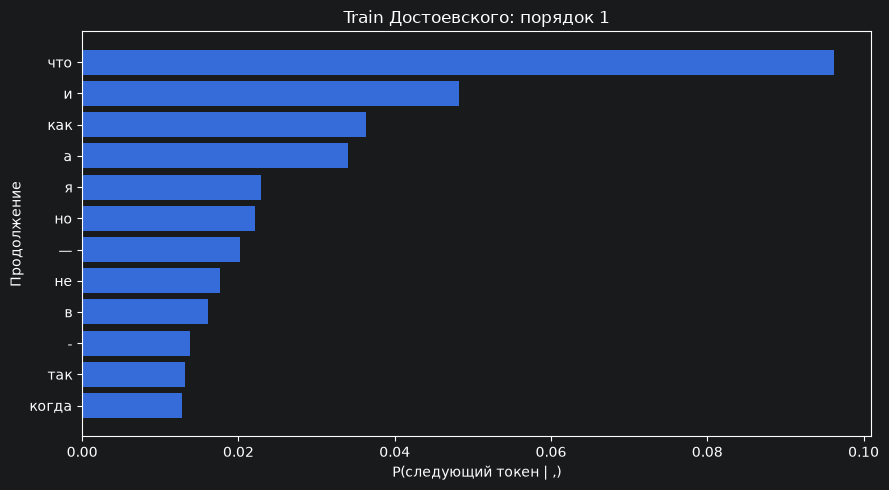

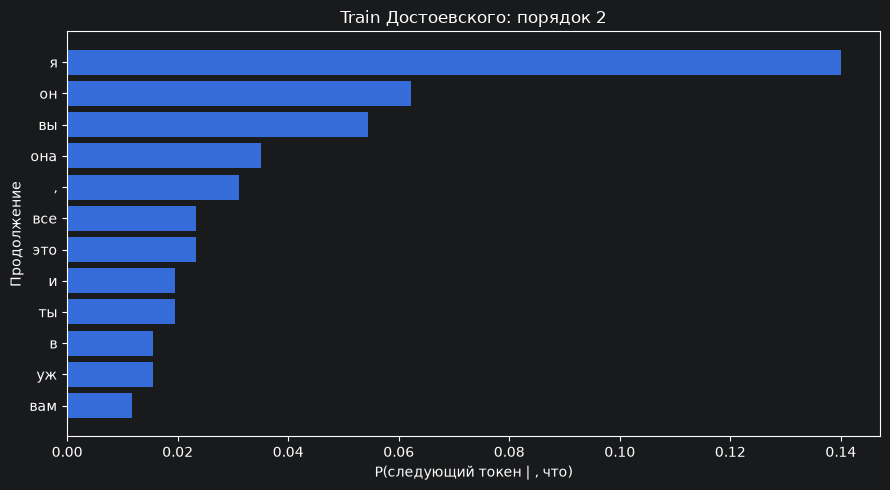

In [53]:
for q in (1, 2):
    context = (
        transitions.filter((F.col("order") == q) & ~F.col("context").contains("<BOS>"))
        .groupBy("context")
        .agg(F.sum("count").alias("n"))
        .orderBy(F.desc("n"), "context")
        .first()
        .context
    )
    options = chain[q, tuple(context.split(" "))]
    total = sum((c for w, c in options))
    top = sorted(options, key=lambda x: (-x[1], x[0]))[:12]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh([w for w, c in top][::-1], [c / total for w, c in top][::-1])
    ax.set(
        xlabel=f"P(следующий токен | {context})",
        ylabel="Продолжение",
        title=f"Train Достоевского: порядок {q}",
    )
    plt.tight_layout()
    plt.show()

**Вывод:** Проверены известный/неизвестный контекст, backoff, повторяемость и обе причины остановки для обоих порядков. Контрольные цепи проверяют EOS и лимит детерминированно. Границы предложений не пересекаются. Эти проверки не измеряют литературную связность.

## 14. Сохранение модели и применение

Сохраняется полный PipelineModel с токенизацией, словарём, IDF/нормированием и классификатором. Для нового произведения повторяются нарезка на 300 слов и усреднение вероятностей.

Функция ниже принимает уже проверенный и очищенный основной текст. Если слов меньше 300, она сообщает об отсутствии полного фрагмента. Проверка после загрузки использует фиксированные train-входы; test для повторной настройки не используется.

In [54]:
MODEL_PATH = OUT / "best_author_pipeline"
BEST_MODEL.write().overwrite().save(MODEL_PATH.as_posix())
loaded = PipelineModel.load(MODEL_PATH.as_posix())
probe = train.orderBy("row_id").select("row_id", "text").limit(5)
a = BEST_MODEL.transform(probe).orderBy("row_id").select("prediction", "probability").collect()
b = loaded.transform(probe).orderBy("row_id").select("prediction", "probability").collect()
for x, y in zip(a, b):
    assert x.prediction == y.prediction
    np.testing.assert_allclose(
        x.probability.toArray(), y.probability.toArray(), rtol=1e-10, atol=1e-12
    )

def predict_work(main_text):
    words = re.findall("(?u)[^\\W_]+", main_text.lower())
    chunks = [" ".join(words[i : i + 300]) for i in range(0, len(words) - 299, 300)]
    if not chunks:
        return dict(author=None, reason="Меньше 300 слов основного текста", fragments=0)
    source = spark.createDataFrame([(i, t) for i, t in enumerate(chunks)], ["i", "text"])
    pred = loaded.transform(source).withColumn("_p", vector_to_array("probability"))
    probabilities = np.array(
        pred.agg(*[F.avg(F.col("_p")[i]).alias(f"p{i}") for i in range(K)]).first()
    )
    return dict(
        author=LABEL_NAMES[int(np.argmax(probabilities))],
        probabilities=probabilities.tolist(),
        fragments=len(chunks),
    )

In [55]:
print("Короткий вход:", predict_work("короткий текст"))
config = dict(
    task="Literature classification and Dostoevsky generation",
    archive_sha256=archive_hash,
    authors=AUTHORS,
    label_names=LABEL_NAMES,
    generator_author=GEN_AUTHOR,
    seed=SEED,
    split="60/20/20 by whole work groups, stratified by author before fragmentation",
    fragment_words=FRAGMENT_WORDS,
    discard_incomplete_tail=True,
    max_train_fragments_per_work=MAX_TRAIN_FRAGMENTS,
    model=BEST_NAME,
    vocab_size=len(cv_best.vocabulary),
    vocab_limit=VOCAB_SIZE,
    min_df=MIN_DF,
    reg_param=REG_PARAM,
    model_parameters={
        p.name: str(v) for p, v in BEST_MODEL.stages[-1].extractParamMap().items()
    },
    test_fragment=TEST_FRAG,
    test_work=TEST_WORK,
    baseline_fragment=BASE_FRAG,
    baseline_work=BASE_WORK,
    generator=dict(
        sentence_limit_per_train_work=GEN_SENTENCES_PER_WORK,
        eligible=N_ELIGIBLE,
        selected=N_SENTENCES,
        max_edges=MAX_EDGES,
        pattern=MARKOV_PATTERN,
        seeds=[7, 42, 101],
        exact_matches=MATCHED,
    ),
    versions=dict(
        python=platform.python_version(),
        spark=spark.version,
        numpy=np.__version__,
        pandas=pd.__version__,
    ),
)

(OUT / "experiment.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)
test_pred.select(
    "row_id", "work_group", "author", "label", "prediction", "probability"
).write.mode("overwrite").parquet((OUT / "test_fragment_predictions").as_posix())
test_works.write.mode("overwrite").parquet((OUT / "test_work_predictions").as_posix())
print("Результаты:", OUT)

Короткий вход: {'author': None, 'reason': 'Меньше 300 слов основного текста', 'fragments': 0}
Результаты: D:\BigData_Practicies\results_pr6_literature


**Вывод:** Полный Pipeline сохранён и загружен обратно. Прогнозы и вероятности на фиксированных train-входах совпали. Сохранены паспорт, разбиение, метрики, предсказания, параметры и таблицы переходов.

## 15. Итоговые выводы и ограничения

Численные результаты формируются по выполненному запуску. Контрольные значения из опытов на отзывах не переносятся на литературный корпус.

1. **Корпус.** Прочитано 373 TXT. Для классификации выбрано 17 файлов Брюсова, 8 Герцена и 9 Пушкина до объединения повторов. Для генерации - 12 произведений Достоевского. Границы, отбор и исключения зафиксированы в паспорте.
2. **Разбиение.** Целые work_group распределены по авторам 60/20/20 до нарезки. Пар с общими 50-словными участками - 0. Пересечений групп и точных 300-словных фрагментов между частями нет. Неполный хвост отброшен, train ограничен 50 фрагментами на группу.
3. **Модели.** Сравнены NB_BOW, LR_BOW, LR_TFIDF и вариант SAFE_STOP. Выбран NB_BOW, macro-F1 valid по фрагментам - 0.8286. Test открыт после фиксации выбора.
4. **Качество.** Macro-F1 test по фрагментам - 0.7772, по произведениям - 1.0000 на 8 группах. Baseline - 0.0353 и 0.2222. На уровне произведений группы имеют равный вес, но малое число групп делает результат чувствительным к каждой ошибке.
5. **Представление.** Словарь выбранной модели - 5486 токенов. OOV и нулевые векторы рассчитаны для всех частей. Служебные слова сравнивались на valid. Имена героев, лицо рассказчика и сюжет влияют на признаки и не тождественны чистому авторскому стилю.
6. **Генерация.** По 1400 предложениям train-Достоевского построены две цепи. Получены шесть текстов при seed=7,42,101, проверены границы, backoff, повторяемость и остановка. Точных совпадений с train-предложениями - 0/6. Локальное соседство не обеспечивает цельный сюжет.
7. **Ограничения.** Отбор произведений, варианты изданий и границы влияют на выводы. Возможны OCR-ошибки, внутритекстовые эпиграфы и неразмеченные редакционные вставки. Проверка перекрытий не выявляет сильно изменённые редакции. Нет повторных групповых разбиений и полного подбора гиперпараметров. Генератор ограничен выбранными предложениями и коротким контекстом.